# Medical Insurance Charges Prediction
## Course-focused regression, honest validation and influence diagnostics

**Objective:** predict recorded `charges` using age, sex, BMI, children, smoking status and region. This is an academic observational-data project, not a causal analysis or a validated insurance-pricing system.

This notebook contains its dataset, runs offline after dependencies are installed, and includes executed outputs. Run **Kernel → Restart Kernel and Run All Cells** to reproduce the analysis. Python 3.11+ is recommended; required packages: pandas, numpy, scipy, scikit-learn, statsmodels, matplotlib, seaborn, IPython.

### Sources and scope
- Dataset and inspected reference notebook: https://github.com/jishen-harilal/insurance-charges-prediction-linear-regression/tree/main
- Repository-attributed source: https://www.kaggle.com/datasets/mirichoi0218/insurance
- Supplied course notes: *Outlier_merged (1)(2).pdf*, physical pages 1–54.

|Verified note material|Pages|Use here|
|---|---:|---|
|Hat matrix and leverage|1–3|Unusual predictor combinations|
|Standardized/studentized residuals|3–4|Unusual response errors|
|Deletion diagnostics and Cook's distance|5–6|Influence assessment|
|Multiple OLS, normal equations, unbiasedness, covariance, BLUE and normal-error MLE|7–14|Main regression foundation|
|Simple OLS|15–17|Background|
|Clustering|18–30|Not needed|
|Factor analysis|31–39|Not needed|
|PCA|40–54|Not needed with these few mixed predictors|

**Explicit extensions:** reference-category encoding, interaction features, cross-validation, MAE/RMSE/predictive R², VIF, robust standard errors, Q–Q/scale-location plots, and conditional log-target modelling with smearing. Ridge/lasso and broad polynomial expansion are excluded. No repository metrics are reused as our results.

### Predeclared decisions
1. Retain the unresolved exact duplicate, but keep identical rows together in every split.
2. Reserve approximately 20% of unique-row groups as a test set, seed 42.
3. Main candidates: all-predictor OLS and OLS with centred BMI × smoker.
4. Consider log-target interaction OLS only if training baseline residual spread differs by at least a factor of 1.5 across fitted-value quartiles. This is a pragmatic extension, not a formal assumption test or proof of a log relationship.
5. Compare candidates on identical five group-preserving training folds. Select the simplest candidate within 1% of the lowest mean validation RMSE. The 1% tolerance is a practical predeclared rule, not a significance test.
6. No outlier deletion or prediction clipping. Freeze selection before test evaluation.


In [1]:
import io, json, hashlib, platform, importlib.metadata
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy import stats
from sklearn.model_selection import GroupShuffleSplit, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi":110, "axes.titlesize":12})
SEED=42
# Export copies only when explicitly enabled; all plots are embedded in notebook outputs.
EXPORT_PLOTS=False
PLOT_DIR=Path("validation_plots")
plot_names=[]
def show_plot(fig, name):
    fig.tight_layout()
    plot_names.append(name)
    if EXPORT_PLOTS:
        PLOT_DIR.mkdir(exist_ok=True)
        fig.savefig(PLOT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
versions={p:importlib.metadata.version(p) for p in
          ["numpy","pandas","scipy","scikit-learn","statsmodels","matplotlib","seaborn"]}
print("Python:",platform.python_version())
display(pd.Series(versions,name="Executed package version").to_frame())

Python: 3.12.14


,Executed package version
numpy,2.3.5
pandas,2.2.3
scipy,1.17.0
scikit-learn,1.8.0
statsmodels,0.15.0
matplotlib,3.10.8
seaborn,0.13.2


## 1. Load and validate the actual dataset
The CSV is embedded for portability. Its checksum refers to the embedded UTF-8 copy; line-ending normalization may differ from GitHub's original bytes. Currency and observation time period are not specified by the CSV; the repository interprets charges as dollars. We label plots in **charge units**.

Missing values, duplicate policy and sample counts are checked rather than assumed. Without identifiers, matching records cannot establish that they refer to the same person.

In [2]:
DATA_CSV='age,sex,bmi,children,smoker,region,charges\n19,female,27.9,0,yes,southwest,16884.924\n18,male,33.77,1,no,southeast,1725.5523\n28,male,33,3,no,southeast,4449.462\n33,male,22.705,0,no,northwest,21984.47061\n32,male,28.88,0,no,northwest,3866.8552\n31,female,25.74,0,no,southeast,3756.6216\n46,female,33.44,1,no,southeast,8240.5896\n37,female,27.74,3,no,northwest,7281.5056\n37,male,29.83,2,no,northeast,6406.4107\n60,female,25.84,0,no,northwest,28923.13692\n25,male,26.22,0,no,northeast,2721.3208\n62,female,26.29,0,yes,southeast,27808.7251\n23,male,34.4,0,no,southwest,1826.843\n56,female,39.82,0,no,southeast,11090.7178\n27,male,42.13,0,yes,southeast,39611.7577\n19,male,24.6,1,no,southwest,1837.237\n52,female,30.78,1,no,northeast,10797.3362\n23,male,23.845,0,no,northeast,2395.17155\n56,male,40.3,0,no,southwest,10602.385\n30,male,35.3,0,yes,southwest,36837.467\n60,female,36.005,0,no,northeast,13228.84695\n30,female,32.4,1,no,southwest,4149.736\n18,male,34.1,0,no,southeast,1137.011\n34,female,31.92,1,yes,northeast,37701.8768\n37,male,28.025,2,no,northwest,6203.90175\n59,female,27.72,3,no,southeast,14001.1338\n63,female,23.085,0,no,northeast,14451.83515\n55,female,32.775,2,no,northwest,12268.63225\n23,male,17.385,1,no,northwest,2775.19215\n31,male,36.3,2,yes,southwest,38711\n22,male,35.6,0,yes,southwest,35585.576\n18,female,26.315,0,no,northeast,2198.18985\n19,female,28.6,5,no,southwest,4687.797\n63,male,28.31,0,no,northwest,13770.0979\n28,male,36.4,1,yes,southwest,51194.55914\n19,male,20.425,0,no,northwest,1625.43375\n62,female,32.965,3,no,northwest,15612.19335\n26,male,20.8,0,no,southwest,2302.3\n35,male,36.67,1,yes,northeast,39774.2763\n60,male,39.9,0,yes,southwest,48173.361\n24,female,26.6,0,no,northeast,3046.062\n31,female,36.63,2,no,southeast,4949.7587\n41,male,21.78,1,no,southeast,6272.4772\n37,female,30.8,2,no,southeast,6313.759\n38,male,37.05,1,no,northeast,6079.6715\n55,male,37.3,0,no,southwest,20630.28351\n18,female,38.665,2,no,northeast,3393.35635\n28,female,34.77,0,no,northwest,3556.9223\n60,female,24.53,0,no,southeast,12629.8967\n36,male,35.2,1,yes,southeast,38709.176\n18,female,35.625,0,no,northeast,2211.13075\n21,female,33.63,2,no,northwest,3579.8287\n48,male,28,1,yes,southwest,23568.272\n36,male,34.43,0,yes,southeast,37742.5757\n40,female,28.69,3,no,northwest,8059.6791\n58,male,36.955,2,yes,northwest,47496.49445\n58,female,31.825,2,no,northeast,13607.36875\n18,male,31.68,2,yes,southeast,34303.1672\n53,female,22.88,1,yes,southeast,23244.7902\n34,female,37.335,2,no,northwest,5989.52365\n43,male,27.36,3,no,northeast,8606.2174\n25,male,33.66,4,no,southeast,4504.6624\n64,male,24.7,1,no,northwest,30166.61817\n28,female,25.935,1,no,northwest,4133.64165\n20,female,22.42,0,yes,northwest,14711.7438\n19,female,28.9,0,no,southwest,1743.214\n61,female,39.1,2,no,southwest,14235.072\n40,male,26.315,1,no,northwest,6389.37785\n40,female,36.19,0,no,southeast,5920.1041\n28,male,23.98,3,yes,southeast,17663.1442\n27,female,24.75,0,yes,southeast,16577.7795\n31,male,28.5,5,no,northeast,6799.458\n53,female,28.1,3,no,southwest,11741.726\n58,male,32.01,1,no,southeast,11946.6259\n44,male,27.4,2,no,southwest,7726.854\n57,male,34.01,0,no,northwest,11356.6609\n29,female,29.59,1,no,southeast,3947.4131\n21,male,35.53,0,no,southeast,1532.4697\n22,female,39.805,0,no,northeast,2755.02095\n41,female,32.965,0,no,northwest,6571.02435\n31,male,26.885,1,no,northeast,4441.21315\n45,female,38.285,0,no,northeast,7935.29115\n22,male,37.62,1,yes,southeast,37165.1638\n48,female,41.23,4,no,northwest,11033.6617\n37,female,34.8,2,yes,southwest,39836.519\n45,male,22.895,2,yes,northwest,21098.55405\n57,female,31.16,0,yes,northwest,43578.9394\n56,female,27.2,0,no,southwest,11073.176\n46,female,27.74,0,no,northwest,8026.6666\n55,female,26.98,0,no,northwest,11082.5772\n21,female,39.49,0,no,southeast,2026.9741\n53,female,24.795,1,no,northwest,10942.13205\n59,male,29.83,3,yes,northeast,30184.9367\n35,male,34.77,2,no,northwest,5729.0053\n64,female,31.3,2,yes,southwest,47291.055\n28,female,37.62,1,no,southeast,3766.8838\n54,female,30.8,3,no,southwest,12105.32\n55,male,38.28,0,no,southeast,10226.2842\n56,male,19.95,0,yes,northeast,22412.6485\n38,male,19.3,0,yes,southwest,15820.699\n41,female,31.6,0,no,southwest,6186.127\n30,male,25.46,0,no,northeast,3645.0894\n18,female,30.115,0,no,northeast,21344.8467\n61,female,29.92,3,yes,southeast,30942.1918\n34,female,27.5,1,no,southwest,5003.853\n20,male,28.025,1,yes,northwest,17560.37975\n19,female,28.4,1,no,southwest,2331.519\n26,male,30.875,2,no,northwest,3877.30425\n29,male,27.94,0,no,southeast,2867.1196\n63,male,35.09,0,yes,southeast,47055.5321\n54,male,33.63,1,no,northwest,10825.2537\n55,female,29.7,2,no,southwest,11881.358\n37,male,30.8,0,no,southwest,4646.759\n21,female,35.72,0,no,northwest,2404.7338\n52,male,32.205,3,no,northeast,11488.31695\n60,male,28.595,0,no,northeast,30259.99556\n58,male,49.06,0,no,southeast,11381.3254\n29,female,27.94,1,yes,southeast,19107.7796\n49,female,27.17,0,no,southeast,8601.3293\n37,female,23.37,2,no,northwest,6686.4313\n44,male,37.1,2,no,southwest,7740.337\n18,male,23.75,0,no,northeast,1705.6245\n20,female,28.975,0,no,northwest,2257.47525\n44,male,31.35,1,yes,northeast,39556.4945\n47,female,33.915,3,no,northwest,10115.00885\n26,female,28.785,0,no,northeast,3385.39915\n19,female,28.3,0,yes,southwest,17081.08\n52,female,37.4,0,no,southwest,9634.538\n32,female,17.765,2,yes,northwest,32734.1863\n38,male,34.7,2,no,southwest,6082.405\n59,female,26.505,0,no,northeast,12815.44495\n61,female,22.04,0,no,northeast,13616.3586\n53,female,35.9,2,no,southwest,11163.568\n19,male,25.555,0,no,northwest,1632.56445\n20,female,28.785,0,no,northeast,2457.21115\n22,female,28.05,0,no,southeast,2155.6815\n19,male,34.1,0,no,southwest,1261.442\n22,male,25.175,0,no,northwest,2045.68525\n54,female,31.9,3,no,southeast,27322.73386\n22,female,36,0,no,southwest,2166.732\n34,male,22.42,2,no,northeast,27375.90478\n26,male,32.49,1,no,northeast,3490.5491\n34,male,25.3,2,yes,southeast,18972.495\n29,male,29.735,2,no,northwest,18157.876\n30,male,28.69,3,yes,northwest,20745.9891\n29,female,38.83,3,no,southeast,5138.2567\n46,male,30.495,3,yes,northwest,40720.55105\n51,female,37.73,1,no,southeast,9877.6077\n53,female,37.43,1,no,northwest,10959.6947\n19,male,28.4,1,no,southwest,1842.519\n35,male,24.13,1,no,northwest,5125.2157\n48,male,29.7,0,no,southeast,7789.635\n32,female,37.145,3,no,northeast,6334.34355\n42,female,23.37,0,yes,northeast,19964.7463\n40,female,25.46,1,no,northeast,7077.1894\n44,male,39.52,0,no,northwest,6948.7008\n48,male,24.42,0,yes,southeast,21223.6758\n18,male,25.175,0,yes,northeast,15518.18025\n30,male,35.53,0,yes,southeast,36950.2567\n50,female,27.83,3,no,southeast,19749.38338\n42,female,26.6,0,yes,northwest,21348.706\n18,female,36.85,0,yes,southeast,36149.4835\n54,male,39.6,1,no,southwest,10450.552\n32,female,29.8,2,no,southwest,5152.134\n37,male,29.64,0,no,northwest,5028.1466\n47,male,28.215,4,no,northeast,10407.08585\n20,female,37,5,no,southwest,4830.63\n32,female,33.155,3,no,northwest,6128.79745\n19,female,31.825,1,no,northwest,2719.27975\n27,male,18.905,3,no,northeast,4827.90495\n63,male,41.47,0,no,southeast,13405.3903\n49,male,30.3,0,no,southwest,8116.68\n18,male,15.96,0,no,northeast,1694.7964\n35,female,34.8,1,no,southwest,5246.047\n24,female,33.345,0,no,northwest,2855.43755\n63,female,37.7,0,yes,southwest,48824.45\n38,male,27.835,2,no,northwest,6455.86265\n54,male,29.2,1,no,southwest,10436.096\n46,female,28.9,2,no,southwest,8823.279\n41,female,33.155,3,no,northeast,8538.28845\n58,male,28.595,0,no,northwest,11735.87905\n18,female,38.28,0,no,southeast,1631.8212\n22,male,19.95,3,no,northeast,4005.4225\n44,female,26.41,0,no,northwest,7419.4779\n44,male,30.69,2,no,southeast,7731.4271\n36,male,41.895,3,yes,northeast,43753.33705\n26,female,29.92,2,no,southeast,3981.9768\n30,female,30.9,3,no,southwest,5325.651\n41,female,32.2,1,no,southwest,6775.961\n29,female,32.11,2,no,northwest,4922.9159\n61,male,31.57,0,no,southeast,12557.6053\n36,female,26.2,0,no,southwest,4883.866\n25,male,25.74,0,no,southeast,2137.6536\n56,female,26.6,1,no,northwest,12044.342\n18,male,34.43,0,no,southeast,1137.4697\n19,male,30.59,0,no,northwest,1639.5631\n39,female,32.8,0,no,southwest,5649.715\n45,female,28.6,2,no,southeast,8516.829\n51,female,18.05,0,no,northwest,9644.2525\n64,female,39.33,0,no,northeast,14901.5167\n19,female,32.11,0,no,northwest,2130.6759\n48,female,32.23,1,no,southeast,8871.1517\n60,female,24.035,0,no,northwest,13012.20865\n27,female,36.08,0,yes,southeast,37133.8982\n46,male,22.3,0,no,southwest,7147.105\n28,female,28.88,1,no,northeast,4337.7352\n59,male,26.4,0,no,southeast,11743.299\n35,male,27.74,2,yes,northeast,20984.0936\n63,female,31.8,0,no,southwest,13880.949\n40,male,41.23,1,no,northeast,6610.1097\n20,male,33,1,no,southwest,1980.07\n40,male,30.875,4,no,northwest,8162.71625\n24,male,28.5,2,no,northwest,3537.703\n34,female,26.73,1,no,southeast,5002.7827\n45,female,30.9,2,no,southwest,8520.026\n41,female,37.1,2,no,southwest,7371.772\n53,female,26.6,0,no,northwest,10355.641\n27,male,23.1,0,no,southeast,2483.736\n26,female,29.92,1,no,southeast,3392.9768\n24,female,23.21,0,no,southeast,25081.76784\n34,female,33.7,1,no,southwest,5012.471\n53,female,33.25,0,no,northeast,10564.8845\n32,male,30.8,3,no,southwest,5253.524\n19,male,34.8,0,yes,southwest,34779.615\n42,male,24.64,0,yes,southeast,19515.5416\n55,male,33.88,3,no,southeast,11987.1682\n28,male,38.06,0,no,southeast,2689.4954\n58,female,41.91,0,no,southeast,24227.33724\n41,female,31.635,1,no,northeast,7358.17565\n47,male,25.46,2,no,northeast,9225.2564\n42,female,36.195,1,no,northwest,7443.64305\n59,female,27.83,3,no,southeast,14001.2867\n19,female,17.8,0,no,southwest,1727.785\n59,male,27.5,1,no,southwest,12333.828\n39,male,24.51,2,no,northwest,6710.1919\n40,female,22.22,2,yes,southeast,19444.2658\n18,female,26.73,0,no,southeast,1615.7667\n31,male,38.39,2,no,southeast,4463.2051\n19,male,29.07,0,yes,northwest,17352.6803\n44,male,38.06,1,no,southeast,7152.6714\n23,female,36.67,2,yes,northeast,38511.6283\n33,female,22.135,1,no,northeast,5354.07465\n55,female,26.8,1,no,southwest,35160.13457\n40,male,35.3,3,no,southwest,7196.867\n63,female,27.74,0,yes,northeast,29523.1656\n54,male,30.02,0,no,northwest,24476.47851\n60,female,38.06,0,no,southeast,12648.7034\n24,male,35.86,0,no,southeast,1986.9334\n19,male,20.9,1,no,southwest,1832.094\n29,male,28.975,1,no,northeast,4040.55825\n18,male,17.29,2,yes,northeast,12829.4551\n63,female,32.2,2,yes,southwest,47305.305\n54,male,34.21,2,yes,southeast,44260.7499\n27,male,30.3,3,no,southwest,4260.744\n50,male,31.825,0,yes,northeast,41097.16175\n55,female,25.365,3,no,northeast,13047.33235\n56,male,33.63,0,yes,northwest,43921.1837\n38,female,40.15,0,no,southeast,5400.9805\n51,male,24.415,4,no,northwest,11520.09985\n19,male,31.92,0,yes,northwest,33750.2918\n58,female,25.2,0,no,southwest,11837.16\n20,female,26.84,1,yes,southeast,17085.2676\n52,male,24.32,3,yes,northeast,24869.8368\n19,male,36.955,0,yes,northwest,36219.40545\n53,female,38.06,3,no,southeast,20462.99766\n46,male,42.35,3,yes,southeast,46151.1245\n40,male,19.8,1,yes,southeast,17179.522\n59,female,32.395,3,no,northeast,14590.63205\n45,male,30.2,1,no,southwest,7441.053\n49,male,25.84,1,no,northeast,9282.4806\n18,male,29.37,1,no,southeast,1719.4363\n50,male,34.2,2,yes,southwest,42856.838\n41,male,37.05,2,no,northwest,7265.7025\n50,male,27.455,1,no,northeast,9617.66245\n25,male,27.55,0,no,northwest,2523.1695\n47,female,26.6,2,no,northeast,9715.841\n19,male,20.615,2,no,northwest,2803.69785\n22,female,24.3,0,no,southwest,2150.469\n59,male,31.79,2,no,southeast,12928.7911\n51,female,21.56,1,no,southeast,9855.1314\n40,female,28.12,1,yes,northeast,22331.5668\n54,male,40.565,3,yes,northeast,48549.17835\n30,male,27.645,1,no,northeast,4237.12655\n55,female,32.395,1,no,northeast,11879.10405\n52,female,31.2,0,no,southwest,9625.92\n46,male,26.62,1,no,southeast,7742.1098\n46,female,48.07,2,no,northeast,9432.9253\n63,female,26.22,0,no,northwest,14256.1928\n59,female,36.765,1,yes,northeast,47896.79135\n52,male,26.4,3,no,southeast,25992.82104\n28,female,33.4,0,no,southwest,3172.018\n29,male,29.64,1,no,northeast,20277.80751\n25,male,45.54,2,yes,southeast,42112.2356\n22,female,28.82,0,no,southeast,2156.7518\n25,male,26.8,3,no,southwest,3906.127\n18,male,22.99,0,no,northeast,1704.5681\n19,male,27.7,0,yes,southwest,16297.846\n47,male,25.41,1,yes,southeast,21978.6769\n31,male,34.39,3,yes,northwest,38746.3551\n48,female,28.88,1,no,northwest,9249.4952\n36,male,27.55,3,no,northeast,6746.7425\n53,female,22.61,3,yes,northeast,24873.3849\n56,female,37.51,2,no,southeast,12265.5069\n28,female,33,2,no,southeast,4349.462\n57,female,38,2,no,southwest,12646.207\n29,male,33.345,2,no,northwest,19442.3535\n28,female,27.5,2,no,southwest,20177.67113\n30,female,33.33,1,no,southeast,4151.0287\n58,male,34.865,0,no,northeast,11944.59435\n41,female,33.06,2,no,northwest,7749.1564\n50,male,26.6,0,no,southwest,8444.474\n19,female,24.7,0,no,southwest,1737.376\n43,male,35.97,3,yes,southeast,42124.5153\n49,male,35.86,0,no,southeast,8124.4084\n27,female,31.4,0,yes,southwest,34838.873\n52,male,33.25,0,no,northeast,9722.7695\n50,male,32.205,0,no,northwest,8835.26495\n54,male,32.775,0,no,northeast,10435.06525\n44,female,27.645,0,no,northwest,7421.19455\n32,male,37.335,1,no,northeast,4667.60765\n34,male,25.27,1,no,northwest,4894.7533\n26,female,29.64,4,no,northeast,24671.66334\n34,male,30.8,0,yes,southwest,35491.64\n57,male,40.945,0,no,northeast,11566.30055\n29,male,27.2,0,no,southwest,2866.091\n40,male,34.105,1,no,northeast,6600.20595\n27,female,23.21,1,no,southeast,3561.8889\n45,male,36.48,2,yes,northwest,42760.5022\n64,female,33.8,1,yes,southwest,47928.03\n52,male,36.7,0,no,southwest,9144.565\n61,female,36.385,1,yes,northeast,48517.56315\n52,male,27.36,0,yes,northwest,24393.6224\n61,female,31.16,0,no,northwest,13429.0354\n56,female,28.785,0,no,northeast,11658.37915\n43,female,35.72,2,no,northeast,19144.57652\n64,male,34.5,0,no,southwest,13822.803\n60,male,25.74,0,no,southeast,12142.5786\n62,male,27.55,1,no,northwest,13937.6665\n50,male,32.3,1,yes,northeast,41919.097\n46,female,27.72,1,no,southeast,8232.6388\n24,female,27.6,0,no,southwest,18955.22017\n62,male,30.02,0,no,northwest,13352.0998\n60,female,27.55,0,no,northeast,13217.0945\n63,male,36.765,0,no,northeast,13981.85035\n49,female,41.47,4,no,southeast,10977.2063\n34,female,29.26,3,no,southeast,6184.2994\n33,male,35.75,2,no,southeast,4889.9995\n46,male,33.345,1,no,northeast,8334.45755\n36,female,29.92,1,no,southeast,5478.0368\n19,male,27.835,0,no,northwest,1635.73365\n57,female,23.18,0,no,northwest,11830.6072\n50,female,25.6,0,no,southwest,8932.084\n30,female,27.7,0,no,southwest,3554.203\n33,male,35.245,0,no,northeast,12404.8791\n18,female,38.28,0,no,southeast,14133.03775\n46,male,27.6,0,no,southwest,24603.04837\n46,male,43.89,3,no,southeast,8944.1151\n47,male,29.83,3,no,northwest,9620.3307\n23,male,41.91,0,no,southeast,1837.2819\n18,female,20.79,0,no,southeast,1607.5101\n48,female,32.3,2,no,northeast,10043.249\n35,male,30.5,1,no,southwest,4751.07\n19,female,21.7,0,yes,southwest,13844.506\n21,female,26.4,1,no,southwest,2597.779\n21,female,21.89,2,no,southeast,3180.5101\n49,female,30.78,1,no,northeast,9778.3472\n56,female,32.3,3,no,northeast,13430.265\n42,female,24.985,2,no,northwest,8017.06115\n44,male,32.015,2,no,northwest,8116.26885\n18,male,30.4,3,no,northeast,3481.868\n61,female,21.09,0,no,northwest,13415.0381\n57,female,22.23,0,no,northeast,12029.2867\n42,female,33.155,1,no,northeast,7639.41745\n26,male,32.9,2,yes,southwest,36085.219\n20,male,33.33,0,no,southeast,1391.5287\n23,female,28.31,0,yes,northwest,18033.9679\n39,female,24.89,3,yes,northeast,21659.9301\n24,male,40.15,0,yes,southeast,38126.2465\n64,female,30.115,3,no,northwest,16455.70785\n62,male,31.46,1,no,southeast,27000.98473\n27,female,17.955,2,yes,northeast,15006.57945\n55,male,30.685,0,yes,northeast,42303.69215\n55,male,33,0,no,southeast,20781.48892\n35,female,43.34,2,no,southeast,5846.9176\n44,male,22.135,2,no,northeast,8302.53565\n19,male,34.4,0,no,southwest,1261.859\n58,female,39.05,0,no,southeast,11856.4115\n50,male,25.365,2,no,northwest,30284.64294\n26,female,22.61,0,no,northwest,3176.8159\n24,female,30.21,3,no,northwest,4618.0799\n48,male,35.625,4,no,northeast,10736.87075\n19,female,37.43,0,no,northwest,2138.0707\n48,male,31.445,1,no,northeast,8964.06055\n49,male,31.35,1,no,northeast,9290.1395\n46,female,32.3,2,no,northeast,9411.005\n46,male,19.855,0,no,northwest,7526.70645\n43,female,34.4,3,no,southwest,8522.003\n21,male,31.02,0,no,southeast,16586.49771\n64,male,25.6,2,no,southwest,14988.432\n18,female,38.17,0,no,southeast,1631.6683\n51,female,20.6,0,no,southwest,9264.797\n47,male,47.52,1,no,southeast,8083.9198\n64,female,32.965,0,no,northwest,14692.66935\n49,male,32.3,3,no,northwest,10269.46\n31,male,20.4,0,no,southwest,3260.199\n52,female,38.38,2,no,northeast,11396.9002\n33,female,24.31,0,no,southeast,4185.0979\n47,female,23.6,1,no,southwest,8539.671\n38,male,21.12,3,no,southeast,6652.5288\n32,male,30.03,1,no,southeast,4074.4537\n19,male,17.48,0,no,northwest,1621.3402\n44,female,20.235,1,yes,northeast,19594.80965\n26,female,17.195,2,yes,northeast,14455.64405\n25,male,23.9,5,no,southwest,5080.096\n19,female,35.15,0,no,northwest,2134.9015\n43,female,35.64,1,no,southeast,7345.7266\n52,male,34.1,0,no,southeast,9140.951\n36,female,22.6,2,yes,southwest,18608.262\n64,male,39.16,1,no,southeast,14418.2804\n63,female,26.98,0,yes,northwest,28950.4692\n64,male,33.88,0,yes,southeast,46889.2612\n61,male,35.86,0,yes,southeast,46599.1084\n40,male,32.775,1,yes,northeast,39125.33225\n25,male,30.59,0,no,northeast,2727.3951\n48,male,30.2,2,no,southwest,8968.33\n45,male,24.31,5,no,southeast,9788.8659\n38,female,27.265,1,no,northeast,6555.07035\n18,female,29.165,0,no,northeast,7323.734819\n21,female,16.815,1,no,northeast,3167.45585\n27,female,30.4,3,no,northwest,18804.7524\n19,male,33.1,0,no,southwest,23082.95533\n29,female,20.235,2,no,northwest,4906.40965\n42,male,26.9,0,no,southwest,5969.723\n60,female,30.5,0,no,southwest,12638.195\n31,male,28.595,1,no,northwest,4243.59005\n60,male,33.11,3,no,southeast,13919.8229\n22,male,31.73,0,no,northeast,2254.7967\n35,male,28.9,3,no,southwest,5926.846\n52,female,46.75,5,no,southeast,12592.5345\n26,male,29.45,0,no,northeast,2897.3235\n31,female,32.68,1,no,northwest,4738.2682\n33,female,33.5,0,yes,southwest,37079.372\n18,male,43.01,0,no,southeast,1149.3959\n59,female,36.52,1,no,southeast,28287.89766\n56,male,26.695,1,yes,northwest,26109.32905\n45,female,33.1,0,no,southwest,7345.084\n60,male,29.64,0,no,northeast,12730.9996\n56,female,25.65,0,no,northwest,11454.0215\n40,female,29.6,0,no,southwest,5910.944\n35,male,38.6,1,no,southwest,4762.329\n39,male,29.6,4,no,southwest,7512.267\n30,male,24.13,1,no,northwest,4032.2407\n24,male,23.4,0,no,southwest,1969.614\n20,male,29.735,0,no,northwest,1769.53165\n32,male,46.53,2,no,southeast,4686.3887\n59,male,37.4,0,no,southwest,21797.0004\n55,female,30.14,2,no,southeast,11881.9696\n57,female,30.495,0,no,northwest,11840.77505\n56,male,39.6,0,no,southwest,10601.412\n40,female,33,3,no,southeast,7682.67\n49,female,36.63,3,no,southeast,10381.4787\n42,male,30,0,yes,southwest,22144.032\n62,female,38.095,2,no,northeast,15230.32405\n56,male,25.935,0,no,northeast,11165.41765\n19,male,25.175,0,no,northwest,1632.03625\n30,female,28.38,1,yes,southeast,19521.9682\n60,female,28.7,1,no,southwest,13224.693\n56,female,33.82,2,no,northwest,12643.3778\n28,female,24.32,1,no,northeast,23288.9284\n18,female,24.09,1,no,southeast,2201.0971\n27,male,32.67,0,no,southeast,2497.0383\n18,female,30.115,0,no,northeast,2203.47185\n19,female,29.8,0,no,southwest,1744.465\n47,female,33.345,0,no,northeast,20878.78443\n54,male,25.1,3,yes,southwest,25382.297\n61,male,28.31,1,yes,northwest,28868.6639\n24,male,28.5,0,yes,northeast,35147.52848\n25,male,35.625,0,no,northwest,2534.39375\n21,male,36.85,0,no,southeast,1534.3045\n23,male,32.56,0,no,southeast,1824.2854\n63,male,41.325,3,no,northwest,15555.18875\n49,male,37.51,2,no,southeast,9304.7019\n18,female,31.35,0,no,southeast,1622.1885\n51,female,39.5,1,no,southwest,9880.068\n48,male,34.3,3,no,southwest,9563.029\n31,female,31.065,0,no,northeast,4347.02335\n54,female,21.47,3,no,northwest,12475.3513\n19,male,28.7,0,no,southwest,1253.936\n44,female,38.06,0,yes,southeast,48885.13561\n53,male,31.16,1,no,northwest,10461.9794\n19,female,32.9,0,no,southwest,1748.774\n61,female,25.08,0,no,southeast,24513.09126\n18,female,25.08,0,no,northeast,2196.4732\n61,male,43.4,0,no,southwest,12574.049\n21,male,25.7,4,yes,southwest,17942.106\n20,male,27.93,0,no,northeast,1967.0227\n31,female,23.6,2,no,southwest,4931.647\n45,male,28.7,2,no,southwest,8027.968\n44,female,23.98,2,no,southeast,8211.1002\n62,female,39.2,0,no,southwest,13470.86\n29,male,34.4,0,yes,southwest,36197.699\n43,male,26.03,0,no,northeast,6837.3687\n51,male,23.21,1,yes,southeast,22218.1149\n19,male,30.25,0,yes,southeast,32548.3405\n38,female,28.93,1,no,southeast,5974.3847\n37,male,30.875,3,no,northwest,6796.86325\n22,male,31.35,1,no,northwest,2643.2685\n21,male,23.75,2,no,northwest,3077.0955\n24,female,25.27,0,no,northeast,3044.2133\n57,female,28.7,0,no,southwest,11455.28\n56,male,32.11,1,no,northeast,11763.0009\n27,male,33.66,0,no,southeast,2498.4144\n51,male,22.42,0,no,northeast,9361.3268\n19,male,30.4,0,no,southwest,1256.299\n39,male,28.3,1,yes,southwest,21082.16\n58,male,35.7,0,no,southwest,11362.755\n20,male,35.31,1,no,southeast,27724.28875\n45,male,30.495,2,no,northwest,8413.46305\n35,female,31,1,no,southwest,5240.765\n31,male,30.875,0,no,northeast,3857.75925\n50,female,27.36,0,no,northeast,25656.57526\n32,female,44.22,0,no,southeast,3994.1778\n51,female,33.915,0,no,northeast,9866.30485\n38,female,37.73,0,no,southeast,5397.6167\n42,male,26.07,1,yes,southeast,38245.59327\n18,female,33.88,0,no,southeast,11482.63485\n19,female,30.59,2,no,northwest,24059.68019\n51,female,25.8,1,no,southwest,9861.025\n46,male,39.425,1,no,northeast,8342.90875\n18,male,25.46,0,no,northeast,1708.0014\n57,male,42.13,1,yes,southeast,48675.5177\n62,female,31.73,0,no,northeast,14043.4767\n59,male,29.7,2,no,southeast,12925.886\n37,male,36.19,0,no,southeast,19214.70553\n64,male,40.48,0,no,southeast,13831.1152\n38,male,28.025,1,no,northeast,6067.12675\n33,female,38.9,3,no,southwest,5972.378\n46,female,30.2,2,no,southwest,8825.086\n46,female,28.05,1,no,southeast,8233.0975\n53,male,31.35,0,no,southeast,27346.04207\n34,female,38,3,no,southwest,6196.448\n20,female,31.79,2,no,southeast,3056.3881\n63,female,36.3,0,no,southeast,13887.204\n54,female,47.41,0,yes,southeast,63770.42801\n54,male,30.21,0,no,northwest,10231.4999\n49,male,25.84,2,yes,northwest,23807.2406\n28,male,35.435,0,no,northeast,3268.84665\n54,female,46.7,2,no,southwest,11538.421\n25,female,28.595,0,no,northeast,3213.62205\n43,female,46.2,0,yes,southeast,45863.205\n63,male,30.8,0,no,southwest,13390.559\n32,female,28.93,0,no,southeast,3972.9247\n62,male,21.4,0,no,southwest,12957.118\n52,female,31.73,2,no,northwest,11187.6567\n25,female,41.325,0,no,northeast,17878.90068\n28,male,23.8,2,no,southwest,3847.674\n46,male,33.44,1,no,northeast,8334.5896\n34,male,34.21,0,no,southeast,3935.1799\n35,female,34.105,3,yes,northwest,39983.42595\n19,male,35.53,0,no,northwest,1646.4297\n46,female,19.95,2,no,northwest,9193.8385\n54,female,32.68,0,no,northeast,10923.9332\n27,male,30.5,0,no,southwest,2494.022\n50,male,44.77,1,no,southeast,9058.7303\n18,female,32.12,2,no,southeast,2801.2588\n19,female,30.495,0,no,northwest,2128.43105\n38,female,40.565,1,no,northwest,6373.55735\n41,male,30.59,2,no,northwest,7256.7231\n49,female,31.9,5,no,southwest,11552.904\n48,male,40.565,2,yes,northwest,45702.02235\n31,female,29.1,0,no,southwest,3761.292\n18,female,37.29,1,no,southeast,2219.4451\n30,female,43.12,2,no,southeast,4753.6368\n62,female,36.86,1,no,northeast,31620.00106\n57,female,34.295,2,no,northeast,13224.05705\n58,female,27.17,0,no,northwest,12222.8983\n22,male,26.84,0,no,southeast,1664.9996\n31,female,38.095,1,yes,northeast,58571.07448\n52,male,30.2,1,no,southwest,9724.53\n25,female,23.465,0,no,northeast,3206.49135\n59,male,25.46,1,no,northeast,12913.9924\n19,male,30.59,0,no,northwest,1639.5631\n39,male,45.43,2,no,southeast,6356.2707\n32,female,23.65,1,no,southeast,17626.23951\n19,male,20.7,0,no,southwest,1242.816\n33,female,28.27,1,no,southeast,4779.6023\n21,male,20.235,3,no,northeast,3861.20965\n34,female,30.21,1,yes,northwest,43943.8761\n61,female,35.91,0,no,northeast,13635.6379\n38,female,30.69,1,no,southeast,5976.8311\n58,female,29,0,no,southwest,11842.442\n47,male,19.57,1,no,northwest,8428.0693\n20,male,31.13,2,no,southeast,2566.4707\n21,female,21.85,1,yes,northeast,15359.1045\n41,male,40.26,0,no,southeast,5709.1644\n46,female,33.725,1,no,northeast,8823.98575\n42,female,29.48,2,no,southeast,7640.3092\n34,female,33.25,1,no,northeast,5594.8455\n43,male,32.6,2,no,southwest,7441.501\n52,female,37.525,2,no,northwest,33471.97189\n18,female,39.16,0,no,southeast,1633.0444\n51,male,31.635,0,no,northwest,9174.13565\n56,female,25.3,0,no,southwest,11070.535\n64,female,39.05,3,no,southeast,16085.1275\n19,female,28.31,0,yes,northwest,17468.9839\n51,female,34.1,0,no,southeast,9283.562\n27,female,25.175,0,no,northeast,3558.62025\n59,female,23.655,0,yes,northwest,25678.77845\n28,male,26.98,2,no,northeast,4435.0942\n30,male,37.8,2,yes,southwest,39241.442\n47,female,29.37,1,no,southeast,8547.6913\n38,female,34.8,2,no,southwest,6571.544\n18,female,33.155,0,no,northeast,2207.69745\n34,female,19,3,no,northeast,6753.038\n20,female,33,0,no,southeast,1880.07\n47,female,36.63,1,yes,southeast,42969.8527\n56,female,28.595,0,no,northeast,11658.11505\n49,male,25.6,2,yes,southwest,23306.547\n19,female,33.11,0,yes,southeast,34439.8559\n55,female,37.1,0,no,southwest,10713.644\n30,male,31.4,1,no,southwest,3659.346\n37,male,34.1,4,yes,southwest,40182.246\n49,female,21.3,1,no,southwest,9182.17\n18,male,33.535,0,yes,northeast,34617.84065\n59,male,28.785,0,no,northwest,12129.61415\n29,female,26.03,0,no,northwest,3736.4647\n36,male,28.88,3,no,northeast,6748.5912\n33,male,42.46,1,no,southeast,11326.71487\n58,male,38,0,no,southwest,11365.952\n44,female,38.95,0,yes,northwest,42983.4585\n53,male,36.1,1,no,southwest,10085.846\n24,male,29.3,0,no,southwest,1977.815\n29,female,35.53,0,no,southeast,3366.6697\n40,male,22.705,2,no,northeast,7173.35995\n51,male,39.7,1,no,southwest,9391.346\n64,male,38.19,0,no,northeast,14410.9321\n19,female,24.51,1,no,northwest,2709.1119\n35,female,38.095,2,no,northeast,24915.04626\n39,male,26.41,0,yes,northeast,20149.3229\n56,male,33.66,4,no,southeast,12949.1554\n33,male,42.4,5,no,southwest,6666.243\n42,male,28.31,3,yes,northwest,32787.45859\n61,male,33.915,0,no,northeast,13143.86485\n23,female,34.96,3,no,northwest,4466.6214\n43,male,35.31,2,no,southeast,18806.14547\n48,male,30.78,3,no,northeast,10141.1362\n39,male,26.22,1,no,northwest,6123.5688\n40,female,23.37,3,no,northeast,8252.2843\n18,male,28.5,0,no,northeast,1712.227\n58,female,32.965,0,no,northeast,12430.95335\n49,female,42.68,2,no,southeast,9800.8882\n53,female,39.6,1,no,southeast,10579.711\n48,female,31.13,0,no,southeast,8280.6227\n45,female,36.3,2,no,southeast,8527.532\n59,female,35.2,0,no,southeast,12244.531\n52,female,25.3,2,yes,southeast,24667.419\n26,female,42.4,1,no,southwest,3410.324\n27,male,33.155,2,no,northwest,4058.71245\n48,female,35.91,1,no,northeast,26392.26029\n57,female,28.785,4,no,northeast,14394.39815\n37,male,46.53,3,no,southeast,6435.6237\n57,female,23.98,1,no,southeast,22192.43711\n32,female,31.54,1,no,northeast,5148.5526\n18,male,33.66,0,no,southeast,1136.3994\n64,female,22.99,0,yes,southeast,27037.9141\n43,male,38.06,2,yes,southeast,42560.4304\n49,male,28.7,1,no,southwest,8703.456\n40,female,32.775,2,yes,northwest,40003.33225\n62,male,32.015,0,yes,northeast,45710.20785\n40,female,29.81,1,no,southeast,6500.2359\n30,male,31.57,3,no,southeast,4837.5823\n29,female,31.16,0,no,northeast,3943.5954\n36,male,29.7,0,no,southeast,4399.731\n41,female,31.02,0,no,southeast,6185.3208\n44,female,43.89,2,yes,southeast,46200.9851\n45,male,21.375,0,no,northwest,7222.78625\n55,female,40.81,3,no,southeast,12485.8009\n60,male,31.35,3,yes,northwest,46130.5265\n56,male,36.1,3,no,southwest,12363.547\n49,female,23.18,2,no,northwest,10156.7832\n21,female,17.4,1,no,southwest,2585.269\n19,male,20.3,0,no,southwest,1242.26\n39,male,35.3,2,yes,southwest,40103.89\n53,male,24.32,0,no,northwest,9863.4718\n33,female,18.5,1,no,southwest,4766.022\n53,male,26.41,2,no,northeast,11244.3769\n42,male,26.125,2,no,northeast,7729.64575\n40,male,41.69,0,no,southeast,5438.7491\n47,female,24.1,1,no,southwest,26236.57997\n27,male,31.13,1,yes,southeast,34806.4677\n21,male,27.36,0,no,northeast,2104.1134\n47,male,36.2,1,no,southwest,8068.185\n20,male,32.395,1,no,northwest,2362.22905\n24,male,23.655,0,no,northwest,2352.96845\n27,female,34.8,1,no,southwest,3577.999\n26,female,40.185,0,no,northwest,3201.24515\n53,female,32.3,2,no,northeast,29186.48236\n41,male,35.75,1,yes,southeast,40273.6455\n56,male,33.725,0,no,northwest,10976.24575\n23,female,39.27,2,no,southeast,3500.6123\n21,female,34.87,0,no,southeast,2020.5523\n50,female,44.745,0,no,northeast,9541.69555\n53,male,41.47,0,no,southeast,9504.3103\n34,female,26.41,1,no,northwest,5385.3379\n47,female,29.545,1,no,northwest,8930.93455\n33,female,32.9,2,no,southwest,5375.038\n51,female,38.06,0,yes,southeast,44400.4064\n49,male,28.69,3,no,northwest,10264.4421\n31,female,30.495,3,no,northeast,6113.23105\n36,female,27.74,0,no,northeast,5469.0066\n18,male,35.2,1,no,southeast,1727.54\n50,female,23.54,2,no,southeast,10107.2206\n43,female,30.685,2,no,northwest,8310.83915\n20,male,40.47,0,no,northeast,1984.4533\n24,female,22.6,0,no,southwest,2457.502\n60,male,28.9,0,no,southwest,12146.971\n49,female,22.61,1,no,northwest,9566.9909\n60,male,24.32,1,no,northwest,13112.6048\n51,female,36.67,2,no,northwest,10848.1343\n58,female,33.44,0,no,northwest,12231.6136\n51,female,40.66,0,no,northeast,9875.6804\n53,male,36.6,3,no,southwest,11264.541\n62,male,37.4,0,no,southwest,12979.358\n19,male,35.4,0,no,southwest,1263.249\n50,female,27.075,1,no,northeast,10106.13425\n30,female,39.05,3,yes,southeast,40932.4295\n41,male,28.405,1,no,northwest,6664.68595\n29,female,21.755,1,yes,northeast,16657.71745\n18,female,40.28,0,no,northeast,2217.6012\n41,female,36.08,1,no,southeast,6781.3542\n35,male,24.42,3,yes,southeast,19361.9988\n53,male,21.4,1,no,southwest,10065.413\n24,female,30.1,3,no,southwest,4234.927\n48,female,27.265,1,no,northeast,9447.25035\n59,female,32.1,3,no,southwest,14007.222\n49,female,34.77,1,no,northwest,9583.8933\n37,female,38.39,0,yes,southeast,40419.0191\n26,male,23.7,2,no,southwest,3484.331\n23,male,31.73,3,yes,northeast,36189.1017\n29,male,35.5,2,yes,southwest,44585.45587\n45,male,24.035,2,no,northeast,8604.48365\n27,male,29.15,0,yes,southeast,18246.4955\n53,male,34.105,0,yes,northeast,43254.41795\n31,female,26.62,0,no,southeast,3757.8448\n50,male,26.41,0,no,northwest,8827.2099\n50,female,30.115,1,no,northwest,9910.35985\n34,male,27,2,no,southwest,11737.84884\n19,male,21.755,0,no,northwest,1627.28245\n47,female,36,1,no,southwest,8556.907\n28,male,30.875,0,no,northwest,3062.50825\n37,female,26.4,0,yes,southeast,19539.243\n21,male,28.975,0,no,northwest,1906.35825\n64,male,37.905,0,no,northwest,14210.53595\n58,female,22.77,0,no,southeast,11833.7823\n24,male,33.63,4,no,northeast,17128.42608\n31,male,27.645,2,no,northeast,5031.26955\n39,female,22.8,3,no,northeast,7985.815\n47,female,27.83,0,yes,southeast,23065.4207\n30,male,37.43,3,no,northeast,5428.7277\n18,male,38.17,0,yes,southeast,36307.7983\n22,female,34.58,2,no,northeast,3925.7582\n23,male,35.2,1,no,southwest,2416.955\n33,male,27.1,1,yes,southwest,19040.876\n27,male,26.03,0,no,northeast,3070.8087\n45,female,25.175,2,no,northeast,9095.06825\n57,female,31.825,0,no,northwest,11842.62375\n47,male,32.3,1,no,southwest,8062.764\n42,female,29,1,no,southwest,7050.642\n64,female,39.7,0,no,southwest,14319.031\n38,female,19.475,2,no,northwest,6933.24225\n61,male,36.1,3,no,southwest,27941.28758\n53,female,26.7,2,no,southwest,11150.78\n44,female,36.48,0,no,northeast,12797.20962\n19,female,28.88,0,yes,northwest,17748.5062\n41,male,34.2,2,no,northwest,7261.741\n51,male,33.33,3,no,southeast,10560.4917\n40,male,32.3,2,no,northwest,6986.697\n45,male,39.805,0,no,northeast,7448.40395\n35,male,34.32,3,no,southeast,5934.3798\n53,male,28.88,0,no,northwest,9869.8102\n30,male,24.4,3,yes,southwest,18259.216\n18,male,41.14,0,no,southeast,1146.7966\n51,male,35.97,1,no,southeast,9386.1613\n50,female,27.6,1,yes,southwest,24520.264\n31,female,29.26,1,no,southeast,4350.5144\n35,female,27.7,3,no,southwest,6414.178\n60,male,36.955,0,no,northeast,12741.16745\n21,male,36.86,0,no,northwest,1917.3184\n29,male,22.515,3,no,northeast,5209.57885\n62,female,29.92,0,no,southeast,13457.9608\n39,female,41.8,0,no,southeast,5662.225\n19,male,27.6,0,no,southwest,1252.407\n22,female,23.18,0,no,northeast,2731.9122\n53,male,20.9,0,yes,southeast,21195.818\n39,female,31.92,2,no,northwest,7209.4918\n27,male,28.5,0,yes,northwest,18310.742\n30,male,44.22,2,no,southeast,4266.1658\n30,female,22.895,1,no,northeast,4719.52405\n58,female,33.1,0,no,southwest,11848.141\n33,male,24.795,0,yes,northeast,17904.52705\n42,female,26.18,1,no,southeast,7046.7222\n64,female,35.97,0,no,southeast,14313.8463\n21,male,22.3,1,no,southwest,2103.08\n18,female,42.24,0,yes,southeast,38792.6856\n23,male,26.51,0,no,southeast,1815.8759\n45,female,35.815,0,no,northwest,7731.85785\n40,female,41.42,1,no,northwest,28476.73499\n19,female,36.575,0,no,northwest,2136.88225\n18,male,30.14,0,no,southeast,1131.5066\n25,male,25.84,1,no,northeast,3309.7926\n46,female,30.8,3,no,southwest,9414.92\n33,female,42.94,3,no,northwest,6360.9936\n54,male,21.01,2,no,southeast,11013.7119\n28,male,22.515,2,no,northeast,4428.88785\n36,male,34.43,2,no,southeast,5584.3057\n20,female,31.46,0,no,southeast,1877.9294\n24,female,24.225,0,no,northwest,2842.76075\n23,male,37.1,3,no,southwest,3597.596\n47,female,26.125,1,yes,northeast,23401.30575\n33,female,35.53,0,yes,northwest,55135.40209\n45,male,33.7,1,no,southwest,7445.918\n26,male,17.67,0,no,northwest,2680.9493\n18,female,31.13,0,no,southeast,1621.8827\n44,female,29.81,2,no,southeast,8219.2039\n60,male,24.32,0,no,northwest,12523.6048\n64,female,31.825,2,no,northeast,16069.08475\n56,male,31.79,2,yes,southeast,43813.8661\n36,male,28.025,1,yes,northeast,20773.62775\n41,male,30.78,3,yes,northeast,39597.4072\n39,male,21.85,1,no,northwest,6117.4945\n63,male,33.1,0,no,southwest,13393.756\n36,female,25.84,0,no,northwest,5266.3656\n28,female,23.845,2,no,northwest,4719.73655\n58,male,34.39,0,no,northwest,11743.9341\n36,male,33.82,1,no,northwest,5377.4578\n42,male,35.97,2,no,southeast,7160.3303\n36,male,31.5,0,no,southwest,4402.233\n56,female,28.31,0,no,northeast,11657.7189\n35,female,23.465,2,no,northeast,6402.29135\n59,female,31.35,0,no,northwest,12622.1795\n21,male,31.1,0,no,southwest,1526.312\n59,male,24.7,0,no,northeast,12323.936\n23,female,32.78,2,yes,southeast,36021.0112\n57,female,29.81,0,yes,southeast,27533.9129\n53,male,30.495,0,no,northeast,10072.05505\n60,female,32.45,0,yes,southeast,45008.9555\n51,female,34.2,1,no,southwest,9872.701\n23,male,50.38,1,no,southeast,2438.0552\n27,female,24.1,0,no,southwest,2974.126\n55,male,32.775,0,no,northwest,10601.63225\n37,female,30.78,0,yes,northeast,37270.1512\n61,male,32.3,2,no,northwest,14119.62\n46,female,35.53,0,yes,northeast,42111.6647\n53,female,23.75,2,no,northeast,11729.6795\n49,female,23.845,3,yes,northeast,24106.91255\n20,female,29.6,0,no,southwest,1875.344\n48,female,33.11,0,yes,southeast,40974.1649\n25,male,24.13,0,yes,northwest,15817.9857\n25,female,32.23,1,no,southeast,18218.16139\n57,male,28.1,0,no,southwest,10965.446\n37,female,47.6,2,yes,southwest,46113.511\n38,female,28,3,no,southwest,7151.092\n55,female,33.535,2,no,northwest,12269.68865\n36,female,19.855,0,no,northeast,5458.04645\n51,male,25.4,0,no,southwest,8782.469\n40,male,29.9,2,no,southwest,6600.361\n18,male,37.29,0,no,southeast,1141.4451\n57,male,43.7,1,no,southwest,11576.13\n61,male,23.655,0,no,northeast,13129.60345\n25,female,24.3,3,no,southwest,4391.652\n50,male,36.2,0,no,southwest,8457.818\n26,female,29.48,1,no,southeast,3392.3652\n42,male,24.86,0,no,southeast,5966.8874\n43,male,30.1,1,no,southwest,6849.026\n44,male,21.85,3,no,northeast,8891.1395\n23,female,28.12,0,no,northwest,2690.1138\n49,female,27.1,1,no,southwest,26140.3603\n33,male,33.44,5,no,southeast,6653.7886\n41,male,28.8,1,no,southwest,6282.235\n37,female,29.5,2,no,southwest,6311.952\n22,male,34.8,3,no,southwest,3443.064\n23,male,27.36,1,no,northwest,2789.0574\n21,female,22.135,0,no,northeast,2585.85065\n51,female,37.05,3,yes,northeast,46255.1125\n25,male,26.695,4,no,northwest,4877.98105\n32,male,28.93,1,yes,southeast,19719.6947\n57,male,28.975,0,yes,northeast,27218.43725\n36,female,30.02,0,no,northwest,5272.1758\n22,male,39.5,0,no,southwest,1682.597\n57,male,33.63,1,no,northwest,11945.1327\n64,female,26.885,0,yes,northwest,29330.98315\n36,female,29.04,4,no,southeast,7243.8136\n54,male,24.035,0,no,northeast,10422.91665\n47,male,38.94,2,yes,southeast,44202.6536\n62,male,32.11,0,no,northeast,13555.0049\n61,female,44,0,no,southwest,13063.883\n43,female,20.045,2,yes,northeast,19798.05455\n19,male,25.555,1,no,northwest,2221.56445\n18,female,40.26,0,no,southeast,1634.5734\n19,female,22.515,0,no,northwest,2117.33885\n49,male,22.515,0,no,northeast,8688.85885\n60,male,40.92,0,yes,southeast,48673.5588\n26,male,27.265,3,no,northeast,4661.28635\n49,male,36.85,0,no,southeast,8125.7845\n60,female,35.1,0,no,southwest,12644.589\n26,female,29.355,2,no,northeast,4564.19145\n27,male,32.585,3,no,northeast,4846.92015\n44,female,32.34,1,no,southeast,7633.7206\n63,male,39.8,3,no,southwest,15170.069\n32,female,24.6,0,yes,southwest,17496.306\n22,male,28.31,1,no,northwest,2639.0429\n18,male,31.73,0,yes,northeast,33732.6867\n59,female,26.695,3,no,northwest,14382.70905\n44,female,27.5,1,no,southwest,7626.993\n33,male,24.605,2,no,northwest,5257.50795\n24,female,33.99,0,no,southeast,2473.3341\n43,female,26.885,0,yes,northwest,21774.32215\n45,male,22.895,0,yes,northeast,35069.37452\n61,female,28.2,0,no,southwest,13041.921\n35,female,34.21,1,no,southeast,5245.2269\n62,female,25,0,no,southwest,13451.122\n62,female,33.2,0,no,southwest,13462.52\n38,male,31,1,no,southwest,5488.262\n34,male,35.815,0,no,northwest,4320.41085\n43,male,23.2,0,no,southwest,6250.435\n50,male,32.11,2,no,northeast,25333.33284\n19,female,23.4,2,no,southwest,2913.569\n57,female,20.1,1,no,southwest,12032.326\n62,female,39.16,0,no,southeast,13470.8044\n41,male,34.21,1,no,southeast,6289.7549\n26,male,46.53,1,no,southeast,2927.0647\n39,female,32.5,1,no,southwest,6238.298\n46,male,25.8,5,no,southwest,10096.97\n45,female,35.3,0,no,southwest,7348.142\n32,male,37.18,2,no,southeast,4673.3922\n59,female,27.5,0,no,southwest,12233.828\n44,male,29.735,2,no,northeast,32108.66282\n39,female,24.225,5,no,northwest,8965.79575\n18,male,26.18,2,no,southeast,2304.0022\n53,male,29.48,0,no,southeast,9487.6442\n18,male,23.21,0,no,southeast,1121.8739\n50,female,46.09,1,no,southeast,9549.5651\n18,female,40.185,0,no,northeast,2217.46915\n19,male,22.61,0,no,northwest,1628.4709\n62,male,39.93,0,no,southeast,12982.8747\n56,female,35.8,1,no,southwest,11674.13\n42,male,35.8,2,no,southwest,7160.094\n37,male,34.2,1,yes,northeast,39047.285\n42,male,31.255,0,no,northwest,6358.77645\n25,male,29.7,3,yes,southwest,19933.458\n57,male,18.335,0,no,northeast,11534.87265\n51,male,42.9,2,yes,southeast,47462.894\n30,female,28.405,1,no,northwest,4527.18295\n44,male,30.2,2,yes,southwest,38998.546\n34,male,27.835,1,yes,northwest,20009.63365\n31,male,39.49,1,no,southeast,3875.7341\n54,male,30.8,1,yes,southeast,41999.52\n24,male,26.79,1,no,northwest,12609.88702\n43,male,34.96,1,yes,northeast,41034.2214\n48,male,36.67,1,no,northwest,28468.91901\n19,female,39.615,1,no,northwest,2730.10785\n29,female,25.9,0,no,southwest,3353.284\n63,female,35.2,1,no,southeast,14474.675\n46,male,24.795,3,no,northeast,9500.57305\n52,male,36.765,2,no,northwest,26467.09737\n35,male,27.1,1,no,southwest,4746.344\n51,male,24.795,2,yes,northwest,23967.38305\n44,male,25.365,1,no,northwest,7518.02535\n21,male,25.745,2,no,northeast,3279.86855\n39,female,34.32,5,no,southeast,8596.8278\n50,female,28.16,3,no,southeast,10702.6424\n34,female,23.56,0,no,northeast,4992.3764\n22,female,20.235,0,no,northwest,2527.81865\n19,female,40.5,0,no,southwest,1759.338\n26,male,35.42,0,no,southeast,2322.6218\n29,male,22.895,0,yes,northeast,16138.76205\n48,male,40.15,0,no,southeast,7804.1605\n26,male,29.15,1,no,southeast,2902.9065\n45,female,39.995,3,no,northeast,9704.66805\n36,female,29.92,0,no,southeast,4889.0368\n54,male,25.46,1,no,northeast,25517.11363\n34,male,21.375,0,no,northeast,4500.33925\n31,male,25.9,3,yes,southwest,19199.944\n27,female,30.59,1,no,northeast,16796.41194\n20,male,30.115,5,no,northeast,4915.05985\n44,female,25.8,1,no,southwest,7624.63\n43,male,30.115,3,no,northwest,8410.04685\n45,female,27.645,1,no,northwest,28340.18885\n34,male,34.675,0,no,northeast,4518.82625\n24,female,20.52,0,yes,northeast,14571.8908\n26,female,19.8,1,no,southwest,3378.91\n38,female,27.835,2,no,northeast,7144.86265\n50,female,31.6,2,no,southwest,10118.424\n38,male,28.27,1,no,southeast,5484.4673\n27,female,20.045,3,yes,northwest,16420.49455\n39,female,23.275,3,no,northeast,7986.47525\n39,female,34.1,3,no,southwest,7418.522\n63,female,36.85,0,no,southeast,13887.9685\n33,female,36.29,3,no,northeast,6551.7501\n36,female,26.885,0,no,northwest,5267.81815\n30,male,22.99,2,yes,northwest,17361.7661\n24,male,32.7,0,yes,southwest,34472.841\n24,male,25.8,0,no,southwest,1972.95\n48,male,29.6,0,no,southwest,21232.18226\n47,male,19.19,1,no,northeast,8627.5411\n29,male,31.73,2,no,northwest,4433.3877\n28,male,29.26,2,no,northeast,4438.2634\n47,male,28.215,3,yes,northwest,24915.22085\n25,male,24.985,2,no,northeast,23241.47453\n51,male,27.74,1,no,northeast,9957.7216\n48,female,22.8,0,no,southwest,8269.044\n43,male,20.13,2,yes,southeast,18767.7377\n61,female,33.33,4,no,southeast,36580.28216\n48,male,32.3,1,no,northwest,8765.249\n38,female,27.6,0,no,southwest,5383.536\n59,male,25.46,0,no,northwest,12124.9924\n19,female,24.605,1,no,northwest,2709.24395\n26,female,34.2,2,no,southwest,3987.926\n54,female,35.815,3,no,northwest,12495.29085\n21,female,32.68,2,no,northwest,26018.95052\n51,male,37,0,no,southwest,8798.593\n22,female,31.02,3,yes,southeast,35595.5898\n47,male,36.08,1,yes,southeast,42211.1382\n18,male,23.32,1,no,southeast,1711.0268\n47,female,45.32,1,no,southeast,8569.8618\n21,female,34.6,0,no,southwest,2020.177\n19,male,26.03,1,yes,northwest,16450.8947\n23,male,18.715,0,no,northwest,21595.38229\n54,male,31.6,0,no,southwest,9850.432\n37,female,17.29,2,no,northeast,6877.9801\n46,female,23.655,1,yes,northwest,21677.28345\n55,female,35.2,0,yes,southeast,44423.803\n30,female,27.93,0,no,northeast,4137.5227\n18,male,21.565,0,yes,northeast,13747.87235\n61,male,38.38,0,no,northwest,12950.0712\n54,female,23,3,no,southwest,12094.478\n22,male,37.07,2,yes,southeast,37484.4493\n45,female,30.495,1,yes,northwest,39725.51805\n22,male,28.88,0,no,northeast,2250.8352\n19,male,27.265,2,no,northwest,22493.65964\n35,female,28.025,0,yes,northwest,20234.85475\n18,male,23.085,0,no,northeast,1704.70015\n20,male,30.685,0,yes,northeast,33475.81715\n28,female,25.8,0,no,southwest,3161.454\n55,male,35.245,1,no,northeast,11394.06555\n43,female,24.7,2,yes,northwest,21880.82\n43,female,25.08,0,no,northeast,7325.0482\n22,male,52.58,1,yes,southeast,44501.3982\n25,female,22.515,1,no,northwest,3594.17085\n49,male,30.9,0,yes,southwest,39727.614\n44,female,36.955,1,no,northwest,8023.13545\n64,male,26.41,0,no,northeast,14394.5579\n49,male,29.83,1,no,northeast,9288.0267\n47,male,29.8,3,yes,southwest,25309.489\n27,female,21.47,0,no,northwest,3353.4703\n55,male,27.645,0,no,northwest,10594.50155\n48,female,28.9,0,no,southwest,8277.523\n45,female,31.79,0,no,southeast,17929.30337\n24,female,39.49,0,no,southeast,2480.9791\n32,male,33.82,1,no,northwest,4462.7218\n24,male,32.01,0,no,southeast,1981.5819\n57,male,27.94,1,no,southeast,11554.2236\n59,male,41.14,1,yes,southeast,48970.2476\n36,male,28.595,3,no,northwest,6548.19505\n29,female,25.6,4,no,southwest,5708.867\n42,female,25.3,1,no,southwest,7045.499\n48,male,37.29,2,no,southeast,8978.1851\n39,male,42.655,0,no,northeast,5757.41345\n63,male,21.66,1,no,northwest,14349.8544\n54,female,31.9,1,no,southeast,10928.849\n37,male,37.07,1,yes,southeast,39871.7043\n63,male,31.445,0,no,northeast,13974.45555\n21,male,31.255,0,no,northwest,1909.52745\n54,female,28.88,2,no,northeast,12096.6512\n60,female,18.335,0,no,northeast,13204.28565\n32,female,29.59,1,no,southeast,4562.8421\n47,female,32,1,no,southwest,8551.347\n21,male,26.03,0,no,northeast,2102.2647\n28,male,31.68,0,yes,southeast,34672.1472\n63,male,33.66,3,no,southeast,15161.5344\n18,male,21.78,2,no,southeast,11884.04858\n32,male,27.835,1,no,northwest,4454.40265\n38,male,19.95,1,no,northwest,5855.9025\n32,male,31.5,1,no,southwest,4076.497\n62,female,30.495,2,no,northwest,15019.76005\n39,female,18.3,5,yes,southwest,19023.26\n55,male,28.975,0,no,northeast,10796.35025\n57,male,31.54,0,no,northwest,11353.2276\n52,male,47.74,1,no,southeast,9748.9106\n56,male,22.1,0,no,southwest,10577.087\n47,male,36.19,0,yes,southeast,41676.0811\n55,female,29.83,0,no,northeast,11286.5387\n23,male,32.7,3,no,southwest,3591.48\n22,female,30.4,0,yes,northwest,33907.548\n50,female,33.7,4,no,southwest,11299.343\n18,female,31.35,4,no,northeast,4561.1885\n51,female,34.96,2,yes,northeast,44641.1974\n22,male,33.77,0,no,southeast,1674.6323\n52,female,30.875,0,no,northeast,23045.56616\n25,female,33.99,1,no,southeast,3227.1211\n33,female,19.095,2,yes,northeast,16776.30405\n53,male,28.6,3,no,southwest,11253.421\n29,male,38.94,1,no,southeast,3471.4096\n58,male,36.08,0,no,southeast,11363.2832\n37,male,29.8,0,no,southwest,20420.60465\n54,female,31.24,0,no,southeast,10338.9316\n49,female,29.925,0,no,northwest,8988.15875\n50,female,26.22,2,no,northwest,10493.9458\n26,male,30,1,no,southwest,2904.088\n45,male,20.35,3,no,southeast,8605.3615\n54,female,32.3,1,no,northeast,11512.405\n38,male,38.39,3,yes,southeast,41949.2441\n48,female,25.85,3,yes,southeast,24180.9335\n28,female,26.315,3,no,northwest,5312.16985\n23,male,24.51,0,no,northeast,2396.0959\n55,male,32.67,1,no,southeast,10807.4863\n41,male,29.64,5,no,northeast,9222.4026\n25,male,33.33,2,yes,southeast,36124.5737\n33,male,35.75,1,yes,southeast,38282.7495\n30,female,19.95,3,no,northwest,5693.4305\n23,female,31.4,0,yes,southwest,34166.273\n46,male,38.17,2,no,southeast,8347.1643\n53,female,36.86,3,yes,northwest,46661.4424\n27,female,32.395,1,no,northeast,18903.49141\n23,female,42.75,1,yes,northeast,40904.1995\n63,female,25.08,0,no,northwest,14254.6082\n55,male,29.9,0,no,southwest,10214.636\n35,female,35.86,2,no,southeast,5836.5204\n34,male,32.8,1,no,southwest,14358.36437\n19,female,18.6,0,no,southwest,1728.897\n39,female,23.87,5,no,southeast,8582.3023\n27,male,45.9,2,no,southwest,3693.428\n57,male,40.28,0,no,northeast,20709.02034\n52,female,18.335,0,no,northwest,9991.03765\n28,male,33.82,0,no,northwest,19673.33573\n50,female,28.12,3,no,northwest,11085.5868\n44,female,25,1,no,southwest,7623.518\n26,female,22.23,0,no,northwest,3176.2877\n33,male,30.25,0,no,southeast,3704.3545\n19,female,32.49,0,yes,northwest,36898.73308\n50,male,37.07,1,no,southeast,9048.0273\n41,female,32.6,3,no,southwest,7954.517\n52,female,24.86,0,no,southeast,27117.99378\n39,male,32.34,2,no,southeast,6338.0756\n50,male,32.3,2,no,southwest,9630.397\n52,male,32.775,3,no,northwest,11289.10925\n60,male,32.8,0,yes,southwest,52590.82939\n20,female,31.92,0,no,northwest,2261.5688\n55,male,21.5,1,no,southwest,10791.96\n42,male,34.1,0,no,southwest,5979.731\n18,female,30.305,0,no,northeast,2203.73595\n58,female,36.48,0,no,northwest,12235.8392\n43,female,32.56,3,yes,southeast,40941.2854\n35,female,35.815,1,no,northwest,5630.45785\n48,female,27.93,4,no,northwest,11015.1747\n36,female,22.135,3,no,northeast,7228.21565\n19,male,44.88,0,yes,southeast,39722.7462\n23,female,23.18,2,no,northwest,14426.07385\n20,female,30.59,0,no,northeast,2459.7201\n32,female,41.1,0,no,southwest,3989.841\n43,female,34.58,1,no,northwest,7727.2532\n34,male,42.13,2,no,southeast,5124.1887\n30,male,38.83,1,no,southeast,18963.17192\n18,female,28.215,0,no,northeast,2200.83085\n41,female,28.31,1,no,northwest,7153.5539\n35,female,26.125,0,no,northeast,5227.98875\n57,male,40.37,0,no,southeast,10982.5013\n29,female,24.6,2,no,southwest,4529.477\n32,male,35.2,2,no,southwest,4670.64\n37,female,34.105,1,no,northwest,6112.35295\n18,male,27.36,1,yes,northeast,17178.6824\n43,female,26.7,2,yes,southwest,22478.6\n56,female,41.91,0,no,southeast,11093.6229\n38,male,29.26,2,no,northwest,6457.8434\n29,male,32.11,2,no,northwest,4433.9159\n22,female,27.1,0,no,southwest,2154.361\n52,female,24.13,1,yes,northwest,23887.6627\n40,female,27.4,1,no,southwest,6496.886\n23,female,34.865,0,no,northeast,2899.48935\n31,male,29.81,0,yes,southeast,19350.3689\n42,female,41.325,1,no,northeast,7650.77375\n24,female,29.925,0,no,northwest,2850.68375\n25,female,30.3,0,no,southwest,2632.992\n48,female,27.36,1,no,northeast,9447.3824\n23,female,28.49,1,yes,southeast,18328.2381\n45,male,23.56,2,no,northeast,8603.8234\n20,male,35.625,3,yes,northwest,37465.34375\n62,female,32.68,0,no,northwest,13844.7972\n43,female,25.27,1,yes,northeast,21771.3423\n23,female,28,0,no,southwest,13126.67745\n31,female,32.775,2,no,northwest,5327.40025\n41,female,21.755,1,no,northeast,13725.47184\n58,female,32.395,1,no,northeast,13019.16105\n48,female,36.575,0,no,northwest,8671.19125\n31,female,21.755,0,no,northwest,4134.08245\n19,female,27.93,3,no,northwest,18838.70366\n19,female,30.02,0,yes,northwest,33307.5508\n41,male,33.55,0,no,southeast,5699.8375\n40,male,29.355,1,no,northwest,6393.60345\n31,female,25.8,2,no,southwest,4934.705\n37,male,24.32,2,no,northwest,6198.7518\n46,male,40.375,2,no,northwest,8733.22925\n22,male,32.11,0,no,northwest,2055.3249\n51,male,32.3,1,no,northeast,9964.06\n18,female,27.28,3,yes,southeast,18223.4512\n35,male,17.86,1,no,northwest,5116.5004\n59,female,34.8,2,no,southwest,36910.60803\n36,male,33.4,2,yes,southwest,38415.474\n37,female,25.555,1,yes,northeast,20296.86345\n59,male,37.1,1,no,southwest,12347.172\n36,male,30.875,1,no,northwest,5373.36425\n39,male,34.1,2,no,southeast,23563.01618\n18,male,21.47,0,no,northeast,1702.4553\n52,female,33.3,2,no,southwest,10806.839\n27,female,31.255,1,no,northwest,3956.07145\n18,male,39.14,0,no,northeast,12890.05765\n40,male,25.08,0,no,southeast,5415.6612\n29,male,37.29,2,no,southeast,4058.1161\n46,female,34.6,1,yes,southwest,41661.602\n38,female,30.21,3,no,northwest,7537.1639\n30,female,21.945,1,no,northeast,4718.20355\n40,male,24.97,2,no,southeast,6593.5083\n50,male,25.3,0,no,southeast,8442.667\n20,female,24.42,0,yes,southeast,26125.67477\n41,male,23.94,1,no,northeast,6858.4796\n33,female,39.82,1,no,southeast,4795.6568\n38,male,16.815,2,no,northeast,6640.54485\n42,male,37.18,2,no,southeast,7162.0122\n56,male,34.43,0,no,southeast,10594.2257\n58,male,30.305,0,no,northeast,11938.25595\n52,male,34.485,3,yes,northwest,60021.39897\n20,female,21.8,0,yes,southwest,20167.33603\n54,female,24.605,3,no,northwest,12479.70895\n58,male,23.3,0,no,southwest,11345.519\n45,female,27.83,2,no,southeast,8515.7587\n26,male,31.065,0,no,northwest,2699.56835\n63,female,21.66,0,no,northeast,14449.8544\n58,female,28.215,0,no,northwest,12224.35085\n37,male,22.705,3,no,northeast,6985.50695\n25,female,42.13,1,no,southeast,3238.4357\n52,male,41.8,2,yes,southeast,47269.854\n64,male,36.96,2,yes,southeast,49577.6624\n22,female,21.28,3,no,northwest,4296.2712\n28,female,33.11,0,no,southeast,3171.6149\n18,male,33.33,0,no,southeast,1135.9407\n28,male,24.3,5,no,southwest,5615.369\n45,female,25.7,3,no,southwest,9101.798\n33,male,29.4,4,no,southwest,6059.173\n18,female,39.82,0,no,southeast,1633.9618\n32,male,33.63,1,yes,northeast,37607.5277\n24,male,29.83,0,yes,northeast,18648.4217\n19,male,19.8,0,no,southwest,1241.565\n20,male,27.3,0,yes,southwest,16232.847\n40,female,29.3,4,no,southwest,15828.82173\n34,female,27.72,0,no,southeast,4415.1588\n42,female,37.9,0,no,southwest,6474.013\n51,female,36.385,3,no,northwest,11436.73815\n54,female,27.645,1,no,northwest,11305.93455\n55,male,37.715,3,no,northwest,30063.58055\n52,female,23.18,0,no,northeast,10197.7722\n32,female,20.52,0,no,northeast,4544.2348\n28,male,37.1,1,no,southwest,3277.161\n41,female,28.05,1,no,southeast,6770.1925\n43,female,29.9,1,no,southwest,7337.748\n49,female,33.345,2,no,northeast,10370.91255\n64,male,23.76,0,yes,southeast,26926.5144\n55,female,30.5,0,no,southwest,10704.47\n24,male,31.065,0,yes,northeast,34254.05335\n20,female,33.3,0,no,southwest,1880.487\n45,male,27.5,3,no,southwest,8615.3\n26,male,33.915,1,no,northwest,3292.52985\n25,female,34.485,0,no,northwest,3021.80915\n43,male,25.52,5,no,southeast,14478.33015\n35,male,27.61,1,no,southeast,4747.0529\n26,male,27.06,0,yes,southeast,17043.3414\n57,male,23.7,0,no,southwest,10959.33\n22,female,30.4,0,no,northeast,2741.948\n32,female,29.735,0,no,northwest,4357.04365\n39,male,29.925,1,yes,northeast,22462.04375\n25,female,26.79,2,no,northwest,4189.1131\n48,female,33.33,0,no,southeast,8283.6807\n47,female,27.645,2,yes,northwest,24535.69855\n18,female,21.66,0,yes,northeast,14283.4594\n18,male,30.03,1,no,southeast,1720.3537\n61,male,36.3,1,yes,southwest,47403.88\n47,female,24.32,0,no,northeast,8534.6718\n28,female,17.29,0,no,northeast,3732.6251\n36,female,25.9,1,no,southwest,5472.449\n20,male,39.4,2,yes,southwest,38344.566\n44,male,34.32,1,no,southeast,7147.4728\n38,female,19.95,2,no,northeast,7133.9025\n19,male,34.9,0,yes,southwest,34828.654\n21,male,23.21,0,no,southeast,1515.3449\n46,male,25.745,3,no,northwest,9301.89355\n58,male,25.175,0,no,northeast,11931.12525\n20,male,22,1,no,southwest,1964.78\n18,male,26.125,0,no,northeast,1708.92575\n28,female,26.51,2,no,southeast,4340.4409\n33,male,27.455,2,no,northwest,5261.46945\n19,female,25.745,1,no,northwest,2710.82855\n45,male,30.36,0,yes,southeast,62592.87309\n62,male,30.875,3,yes,northwest,46718.16325\n25,female,20.8,1,no,southwest,3208.787\n43,male,27.8,0,yes,southwest,37829.7242\n42,male,24.605,2,yes,northeast,21259.37795\n24,female,27.72,0,no,southeast,2464.6188\n29,female,21.85,0,yes,northeast,16115.3045\n32,male,28.12,4,yes,northwest,21472.4788\n25,female,30.2,0,yes,southwest,33900.653\n41,male,32.2,2,no,southwest,6875.961\n42,male,26.315,1,no,northwest,6940.90985\n33,female,26.695,0,no,northwest,4571.41305\n34,male,42.9,1,no,southwest,4536.259\n19,female,34.7,2,yes,southwest,36397.576\n30,female,23.655,3,yes,northwest,18765.87545\n18,male,28.31,1,no,northeast,11272.33139\n19,female,20.6,0,no,southwest,1731.677\n18,male,53.13,0,no,southeast,1163.4627\n35,male,39.71,4,no,northeast,19496.71917\n39,female,26.315,2,no,northwest,7201.70085\n31,male,31.065,3,no,northwest,5425.02335\n62,male,26.695,0,yes,northeast,28101.33305\n62,male,38.83,0,no,southeast,12981.3457\n42,female,40.37,2,yes,southeast,43896.3763\n31,male,25.935,1,no,northwest,4239.89265\n61,male,33.535,0,no,northeast,13143.33665\n42,female,32.87,0,no,northeast,7050.0213\n51,male,30.03,1,no,southeast,9377.9047\n23,female,24.225,2,no,northeast,22395.74424\n52,male,38.6,2,no,southwest,10325.206\n57,female,25.74,2,no,southeast,12629.1656\n23,female,33.4,0,no,southwest,10795.93733\n52,female,44.7,3,no,southwest,11411.685\n50,male,30.97,3,no,northwest,10600.5483\n18,female,31.92,0,no,northeast,2205.9808\n18,female,36.85,0,no,southeast,1629.8335\n21,female,25.8,0,no,southwest,2007.945\n61,female,29.07,0,yes,northwest,29141.3603\n'
EXPECTED_SHA='6e3894cf7d9210613f62c866684055decea694345cd4f244ecd7167041578c68'
assert hashlib.sha256(DATA_CSV.encode()).hexdigest()==EXPECTED_SHA
raw=pd.read_csv(io.StringIO(DATA_CSV))
assert raw.columns.tolist()==["age","sex","bmi","children","smoker","region","charges"]
assert raw.shape==(1338,7)
assert not raw.isna().any().any()
assert np.isfinite(raw[["age","bmi","children","charges"]].to_numpy()).all()
assert (raw.charges>0).all()
assert set(raw.sex)=={"female","male"}
assert set(raw.smoker)=={"yes","no"}
assert set(raw.region)=={"northeast","northwest","southeast","southwest"}
assert raw.age.between(18,64).all() and raw.children.between(0,5).all()
assert (raw.bmi>0).all()
groups=pd.factorize(pd.MultiIndex.from_frame(raw))[0]
print("Rows, columns:",raw.shape," Exact repeated rows:",raw.duplicated().sum())
print("Embedded data SHA256:",EXPECTED_SHA)
display(raw.head())
display(raw.loc[raw.duplicated(keep=False)].assign(original_row=lambda d:d.index))
tr,te=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED).split(raw,groups=groups))
train=raw.iloc[tr].copy(); test=raw.iloc[te].copy()
gtrain=groups[tr]; gtest=groups[te]
assert set(gtrain).isdisjoint(gtest)
print(f"Training rows: {len(train)}; reserved test rows: {len(test)}")
# Do not inspect test outcomes until after selection is frozen.
display(train.describe(include="all"))

Rows, columns: (1338, 7)  Exact repeated rows: 1
Embedded data SHA256: 6e3894cf7d9210613f62c866684055decea694345cd4f244ecd7167041578c68
Training rows: 1070; reserved test rows: 268


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


,age,sex,bmi,children,smoker,region,charges,original_row
195,19,male,30.59,0,no,northwest,1639.5631,195
581,19,male,30.59,0,no,northwest,1639.5631,581


,age,sex,bmi,children,smoker,region,charges
count,1070.000000,1070,1070.000000,1070.000000,1070,1070,1070.000000
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,551,NaN,NaN,856,287,NaN
mean,39.179439,NaN,30.540472,1.083178,NaN,NaN,13019.557911
std,14.005663,NaN,6.049010,1.194624,NaN,NaN,11706.234608
min,18.000000,NaN,15.960000,0.000000,NaN,NaN,1121.873900
25%,27.000000,NaN,26.185000,0.000000,NaN,NaN,4740.464375
50%,39.000000,NaN,30.200000,1.000000,NaN,NaN,9289.083100
75%,51.000000,NaN,34.430000,2.000000,NaN,NaN,16443.294663


## 2. Exploratory analysis — training data only
Numerical predictors need not be normally distributed. High charges are not automatically erroneous outliers. All relationship exploration below uses the training partition.

Read the boxplots as marginal group comparisons, not adjusted effects. The smoker-coloured scatterplots motivate testing BMI × smoker. The numerical heatmap omits categorical variables and cannot establish that all multicollinearity is absent. Boxplot fliers are distribution-based flags, not evidence of data-entry errors.

Training charges mean: 13019.56; median: 9289.08; sample skewness: 1.510
Marginal correlations do not establish causality or rule out design-matrix multicollinearity.


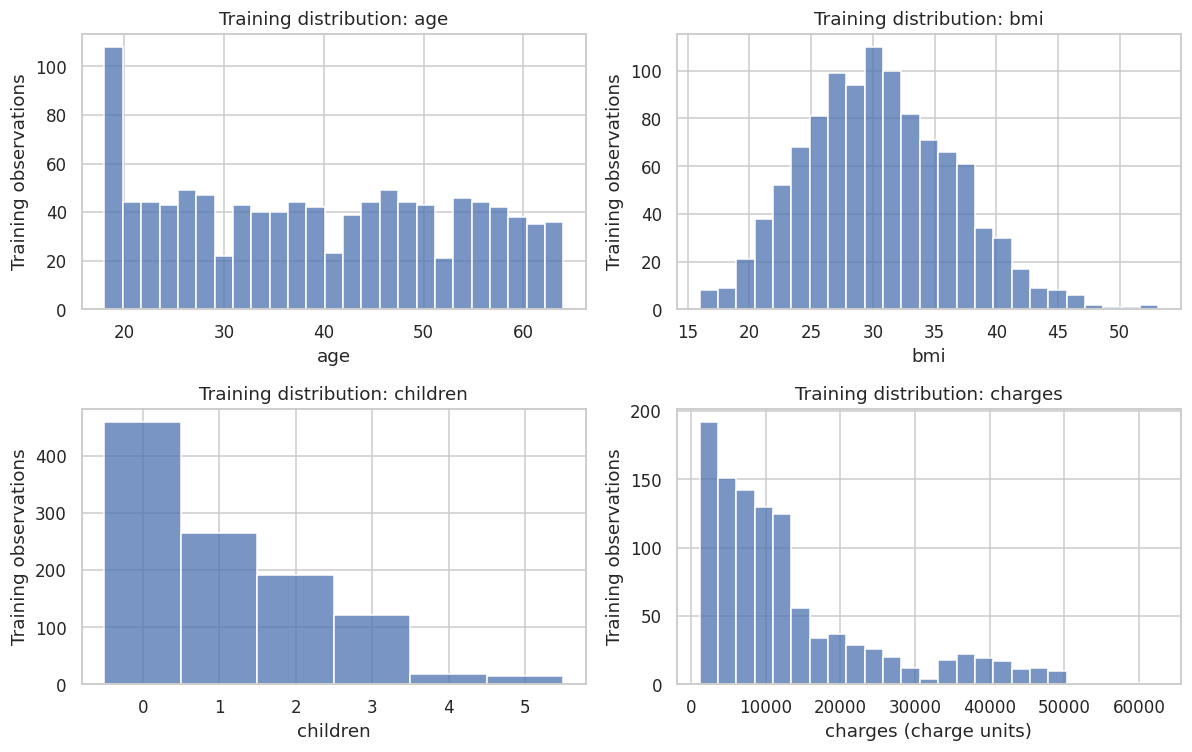

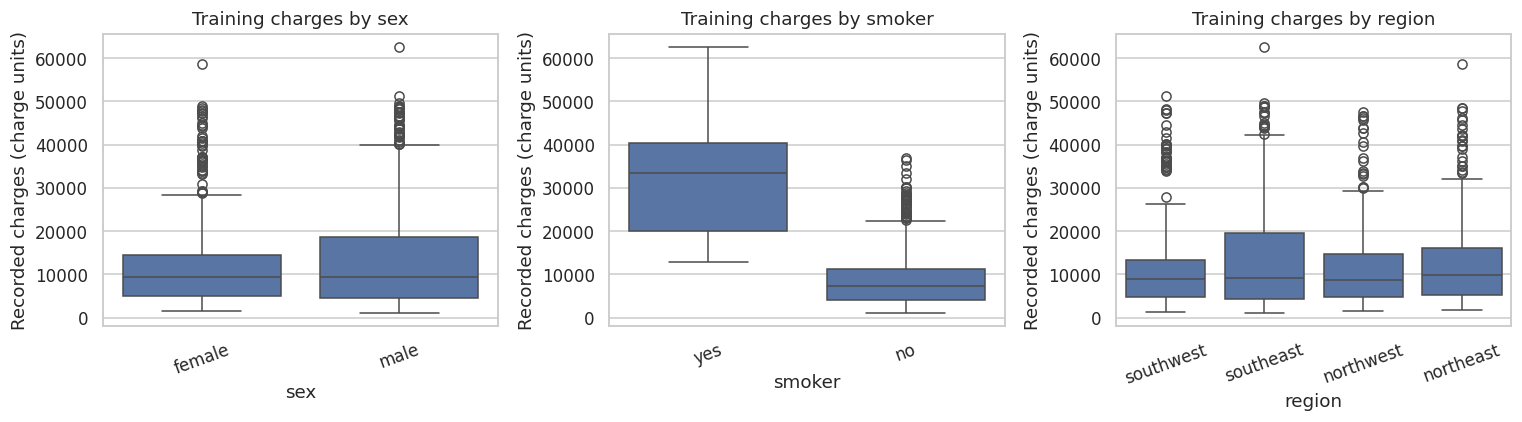

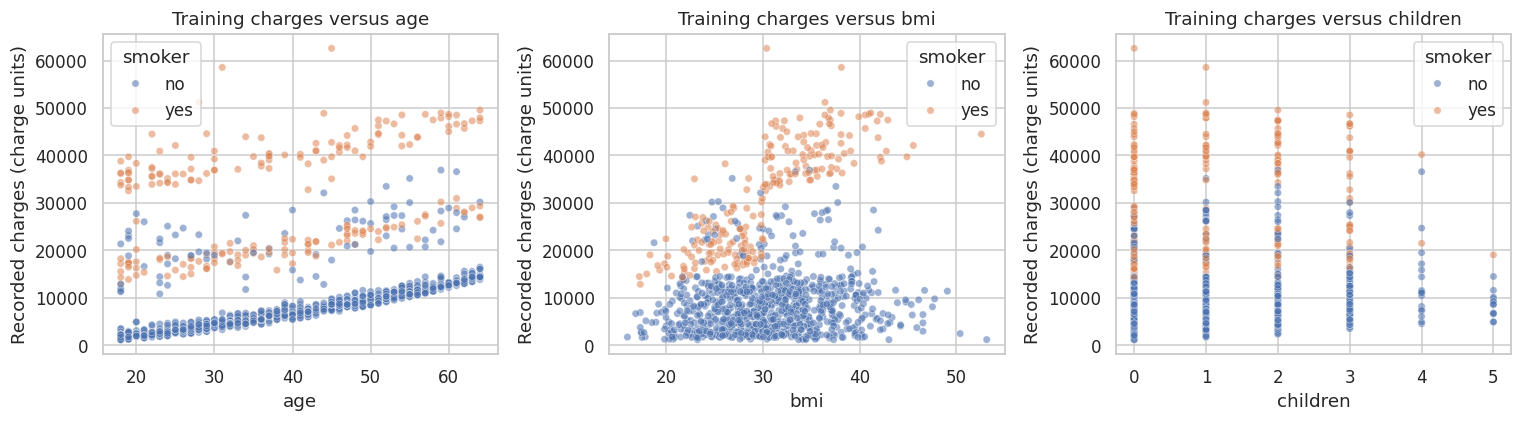

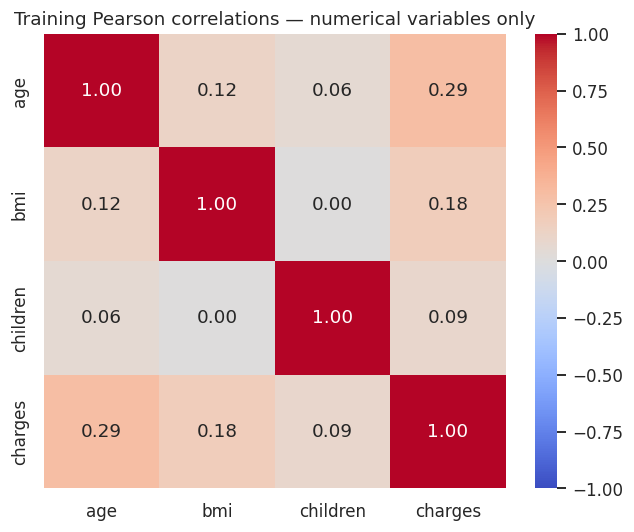

In [3]:
fig,axes=plt.subplots(2,2,figsize=(11,7))
for ax,col in zip(axes.flat,["age","bmi","children","charges"]):
    sns.histplot(data=train,x=col,bins=25 if col!="children" else np.arange(-.5,6.5),ax=ax)
    ax.set(xlabel=col+(" (charge units)" if col=="charges" else ""),ylabel="Training observations",title=f"Training distribution: {col}")
show_plot(fig,"01_distributions")
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,col in zip(axes,["sex","smoker","region"]):
    sns.boxplot(data=train,x=col,y="charges",ax=ax)
    ax.set(xlabel=col,ylabel="Recorded charges (charge units)",title=f"Training charges by {col}")
    ax.tick_params(axis="x",rotation=20)
show_plot(fig,"02_categorical_groups")
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,col in zip(axes,["age","bmi","children"]):
    sns.scatterplot(data=train,x=col,y="charges",hue="smoker",hue_order=["no","yes"],alpha=.55,s=23,ax=ax)
    ax.set(xlabel=col,ylabel="Recorded charges (charge units)",title=f"Training charges versus {col}")
show_plot(fig,"03_relationships")
fig,ax=plt.subplots(figsize=(6,5))
sns.heatmap(train[["age","bmi","children","charges"]].corr(),annot=True,fmt=".2f",vmin=-1,vmax=1,cmap="coolwarm",ax=ax)
ax.set_title("Training Pearson correlations — numerical variables only")
show_plot(fig,"04_correlations")
print(f"Training charges mean: {train.charges.mean():.2f}; median: {train.charges.median():.2f}; sample skewness: {train.charges.skew():.3f}")
print("Marginal correlations do not establish causality or rule out design-matrix multicollinearity.")

## 3. Model mathematics, encoding and fitting
For OLS, \(y=X\beta+\varepsilon\) and \(\hat\beta=\arg\min_\beta\sum_i(y_i-x_i^\top\beta)^2\). If full rank, the theoretical solution is \((X^\top X)^{-1}X^\top y\); library solvers avoid explicitly computing that inverse.

References are female, non-smoker and northeast. Age, BMI and children are centred using the fitting data only. Scaling is not necessary for ordinary OLS. Centering changes interpretation, not the baseline model's available predictions.

The interaction adds \(\beta_{bs}(BMI-\overline{BMI}_{fit})s\). Non-smoker BMI slope is \(\beta_b\); smoker slope is \(\beta_b+\beta_{bs}\). Constituent main effects remain included.

The optional log model fits squared errors in log charges. Original-scale mean predictions use a training-residual smearing factor \(S=n^{-1}\sum_i\exp(u_i)\): \(\hat y=S\exp(\widehat{\log y})\). A global factor assumes the multiplicative error correction is transferable across predictors; it may be inadequate under conditional heteroscedasticity. Validation on the original scale assesses practical usefulness but does not prove this assumption.

In [4]:
NUM=["age","bmi","children"]
REGIONS=["northwest","southeast","southwest"]
def design(data,means,interaction=False):
    d=pd.DataFrame(index=data.index)
    d["const"]=1.0
    for c in NUM:d[c+"_c"]=data[c]-means[c]
    d["sex_male"]=(data.sex=="male").astype(float)
    d["smoker_yes"]=(data.smoker=="yes").astype(float)
    for r in REGIONS:d["region_"+r]=(data.region==r).astype(float)
    if interaction:d["bmi_c_x_smoker"]=d.bmi_c*d.smoker_yes
    return d.astype(float)
def fit_model(data,name):
    means=data[NUM].mean()
    x=design(data,means,interaction=name!="OLS baseline")
    assert np.linalg.matrix_rank(x)==x.shape[1]
    target=np.log(data.charges) if name=="Log interaction OLS" else data.charges
    fitted=sm.OLS(target,x).fit()
    smear=float(np.mean(np.exp(fitted.resid))) if name=="Log interaction OLS" else 1.0
    return {"fit":fitted,"means":means,"name":name,"smear":smear}
def predict_model(model,data):
    x=design(data,model["means"],interaction=model["name"]!="OLS baseline")
    pred=np.asarray(model["fit"].predict(x))
    return np.exp(pred)*model["smear"] if model["name"]=="Log interaction OLS" else pred

def metrics(y,pred):
    y=np.asarray(y);pred=np.asarray(pred);e=y-pred
    result={"MAE":mean_absolute_error(y,pred),"MSE":mean_squared_error(y,pred),
            "RMSE":np.sqrt(mean_squared_error(y,pred)),"R2":r2_score(y,pred)}
    manual=[np.mean(abs(e)),np.mean(e**2),np.sqrt(np.mean(e**2)),1-np.sum(e**2)/np.sum((y-y.mean())**2)]
    np.testing.assert_allclose(list(result.values()),manual,rtol=1e-12,atol=1e-8)
    return result

baseline=fit_model(train,"OLS baseline")
xbase=design(train,baseline["means"])
base_res=np.asarray(baseline["fit"].resid)
spread=pd.DataFrame({"fitted":baseline["fit"].fittedvalues,"residual":base_res})
spread["fitted_quartile"]=pd.qcut(spread.fitted,4,labels=["Q1","Q2","Q3","Q4"])
spread_table=spread.groupby("fitted_quartile",observed=True).residual.agg(["count","std"])
spread_ratio=spread_table["std"].max()/spread_table["std"].min()
log_eligible=bool(spread_ratio>=1.5)
candidates=["OLS baseline","Interaction OLS"]+(["Log interaction OLS"] if log_eligible else [])
display(spread_table)
print(f"Baseline training residual spread ratio: {spread_ratio:.3f}. Log comparison eligible: {log_eligible}.")
print("Candidate list:",candidates)
vif=pd.DataFrame({"term":xbase.columns[1:],"VIF":[variance_inflation_factor(xbase.to_numpy(),j) for j in range(1,xbase.shape[1])]})
display(vif)
print("Centred baseline design condition number:",np.linalg.cond(xbase))

Baseline training residual spread ratio: 1.799. Log comparison eligible: True.
Candidate list: ['OLS baseline', 'Interaction OLS', 'Log interaction OLS']
Centred baseline design condition number: 64.12691125056419


,count,std
fitted_quartile,,
Q1,268,5269.962740
Q2,267,4743.692111
Q3,267,4844.587685
Q4,268,8531.754991


,term,VIF
0,age_c,1.023947
1,bmi_c,1.110670
2,children_c,1.005005
3,sex_male,1.011196
4,smoker_yes,1.018263
5,region_northwest,1.544590
6,region_southeast,1.679437
7,region_southwest,1.555739


## 4. Group-preserving validation and frozen selection
Five shuffled folds are constructed from unique-row groups. Identical records cannot cross a fitting/validation boundary. Every fold recomputes centering and, for the log candidate, smearing using its fitting rows only. Categories are predeclared from the verified schema, not learned from test outcomes.

Mean fold RMSE governs selection. Pooled out-of-fold metrics are also reported; pooled RMSE is not generally equal to the arithmetic mean of fold RMSEs. Fold standard deviations describe variability and are not confidence intervals. This is a student-scale internal comparison; nested CV would be needed for a separate unbiased estimate of the entire selection procedure. The untouched test set provides the final assessment.

FROZEN selection: Interaction OLS


,RMSE_mean,RMSE_sd,MAE_mean,R2_mean
model,,,,
OLS baseline,6107.196,469.212,4210.733,0.727
Interaction OLS,4909.398,523.122,2986.015,0.823
Log interaction OLS,10622.508,1751.692,5193.148,0.158


,MAE,MSE,RMSE,R2
OLS baseline,4211.146,3.747738e+07,6121.877,0.726
Interaction OLS,2986.322,2.432340e+07,4931.876,0.822
Log interaction OLS,5192.546,1.152520e+08,10735.548,0.158


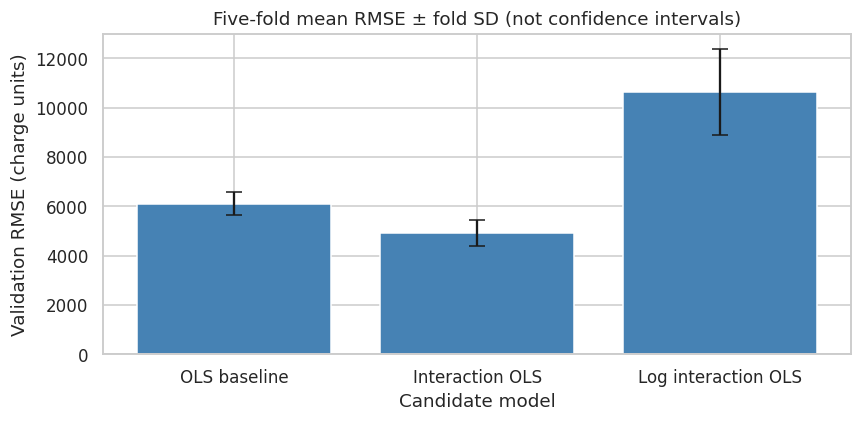

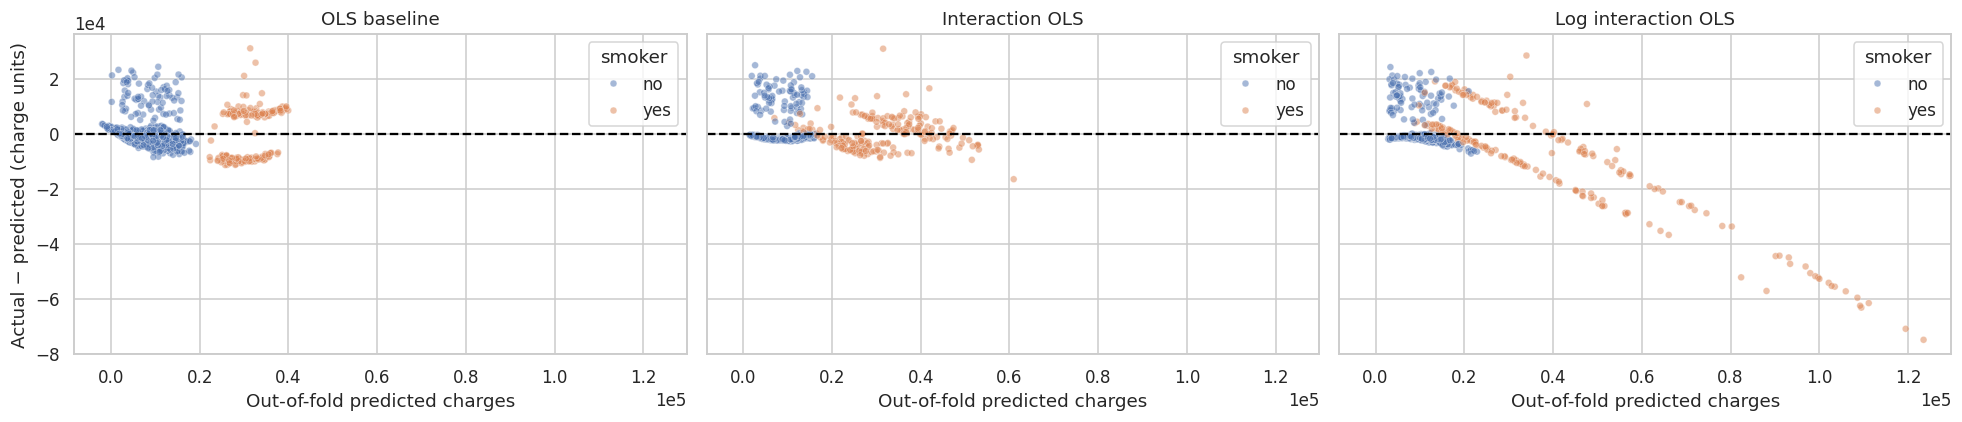

In [5]:
ugroups=np.unique(gtrain)
folds=[]
for a,b in KFold(n_splits=5,shuffle=True,random_state=SEED).split(ugroups):
    fi=np.flatnonzero(np.isin(gtrain,ugroups[a]));vi=np.flatnonzero(np.isin(gtrain,ugroups[b]))
    assert set(gtrain[fi]).isdisjoint(gtrain[vi])
    folds.append((fi,vi))
records=[];oof={};fitted_models={}
for name in candidates:
    predictions=np.full(len(train),np.nan)
    for k,(fi,vi) in enumerate(folds,1):
        model=fit_model(train.iloc[fi],name)
        pred=predict_model(model,train.iloc[vi])
        assert np.isfinite(pred).all()
        predictions[vi]=pred
        records.append({"model":name,"fold":k,**metrics(train.iloc[vi].charges,pred)})
    assert np.isfinite(predictions).all()
    oof[name]=predictions
    fitted_models[name]=fit_model(train,name)
cv=pd.DataFrame(records)
summary=cv.groupby("model",sort=False).agg(RMSE_mean=("RMSE","mean"),RMSE_sd=("RMSE","std"),MAE_mean=("MAE","mean"),R2_mean=("R2","mean"))
pooled=pd.DataFrame({name:metrics(train.charges,p) for name,p in oof.items()}).T
best_rmse=summary.RMSE_mean.min()
eligible=set(summary.index[summary.RMSE_mean<=1.01*best_rmse])
selected_name=next(name for name in candidates if name in eligible)
selected=fitted_models[selected_name]
selection_frozen=True
display(summary.round(3));display(pooled.round(3))
print("FROZEN selection:",selected_name)
fig,ax=plt.subplots(figsize=(8,4))
ax.bar(summary.index,summary.RMSE_mean,yerr=summary.RMSE_sd,capsize=5,color="steelblue")
ax.set(xlabel="Candidate model",ylabel="Validation RMSE (charge units)",title="Five-fold mean RMSE ± fold SD (not confidence intervals)")
show_plot(fig,"05_validation_comparison")
fig,axes=plt.subplots(1,len(candidates),figsize=(6*len(candidates),4),squeeze=False,sharex=True,sharey=True)
for ax,name in zip(axes.flat,candidates):
    sns.scatterplot(x=oof[name],y=train.charges.to_numpy()-oof[name],hue=train.smoker.to_numpy(),hue_order=["no","yes"],alpha=.5,s=20,ax=ax)
    ax.axhline(0,color="black",linestyle="--")
    ax.set(xlabel="Out-of-fold predicted charges",ylabel="Actual − predicted (charge units)",title=name)
    ax.legend(title="smoker")
    ax.ticklabel_format(axis="both",style="sci",scilimits=(0,0))
show_plot(fig,"06_oof_residuals")

## 5. Course-based residual and influence diagnostics
Diagnostics below use the final selected model fitted on training data. For the log model, its OLS residuals and Cook's distances concern **log charges**, not the smeared original-scale prediction function.

\(H=X(X^\top X)^{-1}X^\top\), \(\sum h_{ii}=p\), and \(s^2=SSE/(n-p)\). Internal standardized residuals are \(r_i/[s\sqrt{1-h_{ii}}]\); externally studentized residuals replace \(s\) by the deleted-observation estimate.

Cook's distance is \(D_i=\frac{r_i^2}{p s^2}\frac{h_{ii}}{(1-h_{ii})^2}\). Leverage \(2p/n\), Cook's distance \(4/n\), and absolute studentized residual 3 are **screening heuristics**, not deletion rules. We retain flagged observations.

OLS unbiasedness requires zero conditional mean and a correctly specified mean model. Homoscedasticity supports the classical covariance/BLUE result; normal errors support exact classical inference. Neither a normal target nor normal predictors are required. Independent sampling cannot be verified without provenance.

Flagged training observations: 104 / 1070; none deleted.
HC3 is an inference extension; it changes standard errors, not predictions. No post-selection p-values are used for model selection.
Fitted design rank: 10 / 10 ; condition number: 64.14304730010058


,original_row,charges,leverage,studentized_residual,cooks_distance,flag
834,1047,44501.39820,0.068007,-3.170995,0.072751,True
1043,1300,62592.87309,0.008768,6.404748,0.034966,True
804,1012,36580.28216,0.012418,4.291508,0.022784,True
457,577,58571.07448,0.018836,3.458550,0.022728,True
412,516,27724.28875,0.006972,5.142660,0.018133,True
181,219,25081.76784,0.009194,4.388524,0.017568,True
966,1206,36910.60803,0.007379,4.691656,0.016045,True
635,806,28476.73499,0.009850,3.970947,0.015472,True
339,430,23082.95533,0.008044,4.346423,0.015066,True
257,321,24671.66334,0.012073,3.520230,0.014982,True


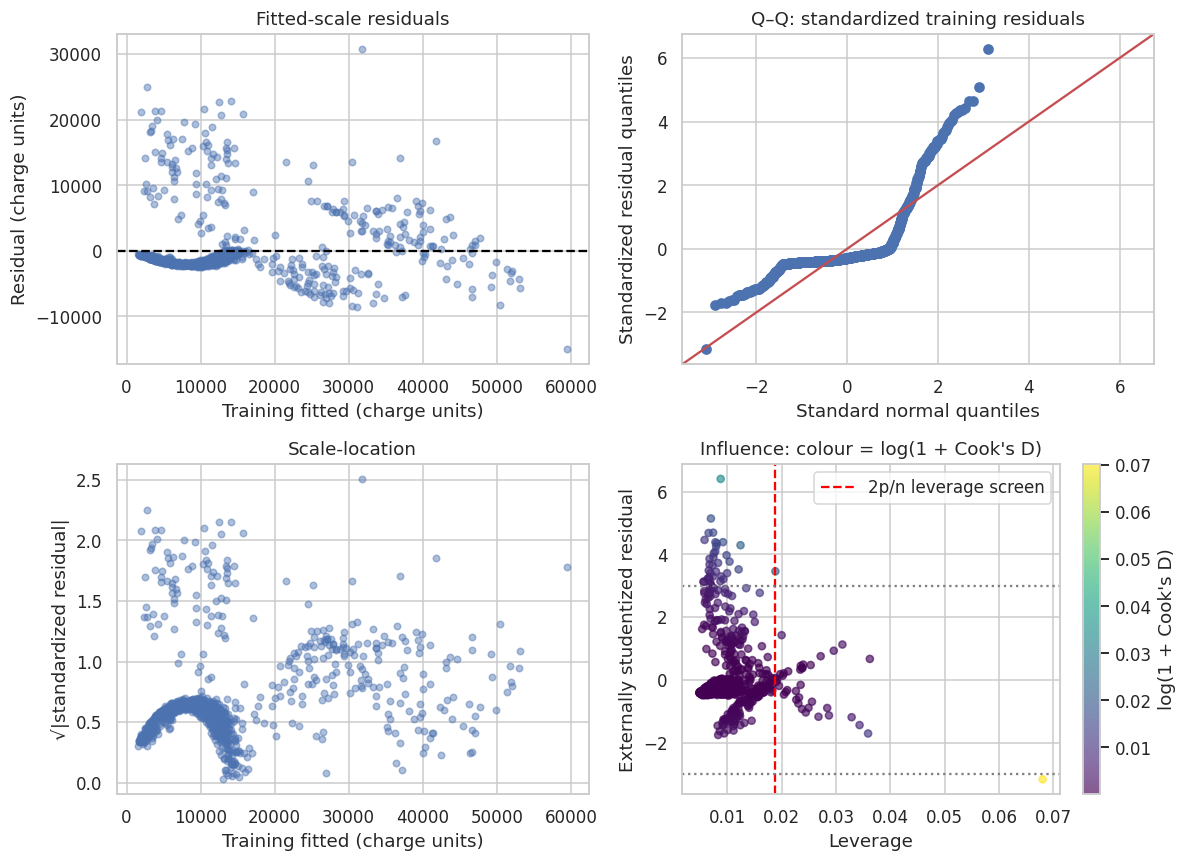

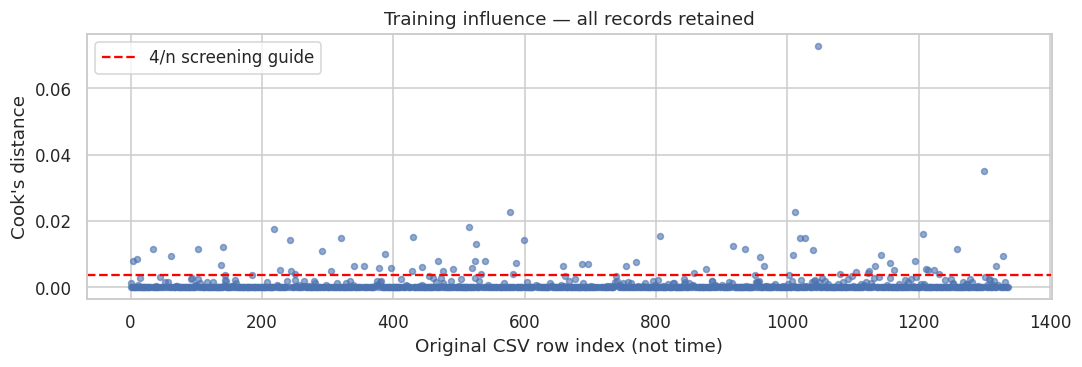

,coefficient,classical_SE,HC3_SE
const,9312.4949,356.9203,367.9831
age_c,259.1149,10.8803,11.1868
bmi_c,12.4418,29.1663,26.1660
children_c,570.5468,126.2751,121.0468
sex_male,-648.6670,303.4563,302.8565
smoker_yes,23409.2404,379.6521,419.0168
region_northwest,-440.9076,433.0151,445.5893
region_southeast,-895.4636,439.9260,463.4275
region_southwest,-884.5124,434.6730,413.7084
bmi_c_x_smoker,1476.6429,61.6612,69.4527


,term,VIF
0,age_c,1.025705
1,bmi_c,1.374884
2,children_c,1.005153
3,sex_male,1.016915
4,smoker_yes,1.019606
5,region_northwest,1.544618
6,region_southeast,1.679486
7,region_southwest,1.556469
8,bmi_c_x_smoker,1.273084


In [6]:
fit=selected["fit"]
xsel=design(train,selected["means"],interaction=selected_name!="OLS baseline")
influence=fit.get_influence()
h=influence.hat_matrix_diag
p=xsel.shape[1];nt=len(train)
resid=np.asarray(fit.resid);fitted=np.asarray(fit.fittedvalues)
s2=np.sum(resid**2)/(nt-p)
std_res=influence.resid_studentized_internal
stud_res=influence.resid_studentized_external
cooks=influence.cooks_distance[0]
manual_h=np.sum(np.asarray(xsel)*np.linalg.pinv(np.asarray(xsel)).T,axis=1)
np.testing.assert_allclose(h,manual_h,rtol=1e-9,atol=1e-10)
np.testing.assert_allclose(h.sum(),p,rtol=1e-10)
np.testing.assert_allclose(std_res,resid/np.sqrt(s2*(1-h)),rtol=1e-9)
np.testing.assert_allclose(cooks,(resid**2/(p*s2))*h/(1-h)**2,rtol=1e-8,atol=1e-10)
# Independent least-squares solver comparison on the fitted scale.
yfit=np.log(train.charges) if selected_name=="Log interaction OLS" else train.charges
beta=np.linalg.lstsq(np.asarray(xsel),np.asarray(yfit),rcond=None)[0]
np.testing.assert_allclose(fit.params,beta,rtol=1e-8,atol=1e-7)
ref=LinearRegression(fit_intercept=False).fit(xsel,yfit)
np.testing.assert_allclose(ref.predict(xsel),fitted,rtol=1e-9,atol=1e-7)
np.testing.assert_allclose(np.asarray(xsel).T@resid,0,atol=1e-4)
assert ((h>=-1e-10)&(h<=1+1e-10)).all()
diagnostic=pd.DataFrame({"original_row":train.index,"charges":train.charges.to_numpy(),"leverage":h,"studentized_residual":stud_res,"cooks_distance":cooks})
diagnostic["flag"]=(h>2*p/nt)|(abs(stud_res)>3)|(cooks>4/nt)
display(diagnostic.sort_values("cooks_distance",ascending=False).head(10))
print(f"Flagged training observations: {diagnostic.flag.sum()} / {nt}; none deleted.")
scale="log charges" if selected_name=="Log interaction OLS" else "charge units"
fig,axes=plt.subplots(2,2,figsize=(11,8))
axes[0,0].scatter(fitted,resid,alpha=.45,s=18);axes[0,0].axhline(0,color="black",ls="--")
axes[0,0].set(xlabel=f"Training fitted ({scale})",ylabel=f"Residual ({scale})",title="Fitted-scale residuals")
sm.qqplot(std_res,line="45",ax=axes[0,1]);axes[0,1].set(title="Q–Q: standardized training residuals",xlabel="Standard normal quantiles",ylabel="Standardized residual quantiles")
axes[1,0].scatter(fitted,np.sqrt(abs(std_res)),alpha=.45,s=18)
axes[1,0].set(xlabel=f"Training fitted ({scale})",ylabel="√|standardized residual|",title="Scale-location")
axes[1,1].scatter(h,stud_res,c=np.log1p(cooks),cmap="viridis",alpha=.65,s=22)
axes[1,1].axvline(2*p/nt,color="red",ls="--",label="2p/n leverage screen")
axes[1,1].axhline(3,color="grey",ls=":");axes[1,1].axhline(-3,color="grey",ls=":")
axes[1,1].set(xlabel="Leverage",ylabel="Externally studentized residual",title="Influence: colour = log(1 + Cook's D)")
axes[1,1].legend()
fig.colorbar(axes[1,1].collections[0],ax=axes[1,1],label="log(1 + Cook's D)")
show_plot(fig,"07_training_diagnostics")
fig,ax=plt.subplots(figsize=(10,3.5))
ax.scatter(train.index,cooks,s=15,alpha=.6);ax.axhline(4/nt,color="red",ls="--",label="4/n screening guide")
ax.set(xlabel="Original CSV row index (not time)",ylabel="Cook's distance",title="Training influence — all records retained")
ax.legend();show_plot(fig,"08_cooks_distance")
robust=fit.get_robustcov_results(cov_type="HC3")
coef=pd.DataFrame({"coefficient":fit.params,"classical_SE":fit.bse,"HC3_SE":robust.bse},index=xsel.columns)
display(coef.round(4))
print("HC3 is an inference extension; it changes standard errors, not predictions. No post-selection p-values are used for model selection.")
print("Fitted design rank:",np.linalg.matrix_rank(xsel),"/",p,"; condition number:",np.linalg.cond(xsel))
display(pd.DataFrame({"term":xsel.columns[1:],"VIF":[variance_inflation_factor(xsel.to_numpy(),j) for j in range(1,p)]}))

## 6. Single final test evaluation
The selected model was frozen before this cell accessed test charges. Only that model is evaluated here, preventing a second model-selection round on test results. Test plots describe performance and limitations; they do not trigger redesign in this notebook.

MAE is mean absolute error; MSE is mean squared error; RMSE is √MSE; predictive R² is 1 − SSE/SST. All are computed on the original charges scale. Negative predictions, if any, are reported without clipping.

Training-mean reference test RMSE: 13613.401
Negative test predictions: 0


,MAE,MSE,RMSE,R2
Training (optimistic),2965.312,2.397535e+07,4896.463,0.825
Pooled OOF,2986.322,2.432340e+07,4931.876,0.822
Reserved test,2828.531,2.091087e+07,4572.841,0.886


,smoker,n,MAE,MSE,RMSE,R2
0,no,208,2282.290,1.536645e+07,3920.006,0.516
1,yes,60,4722.165,4.013154e+07,6334.946,0.714


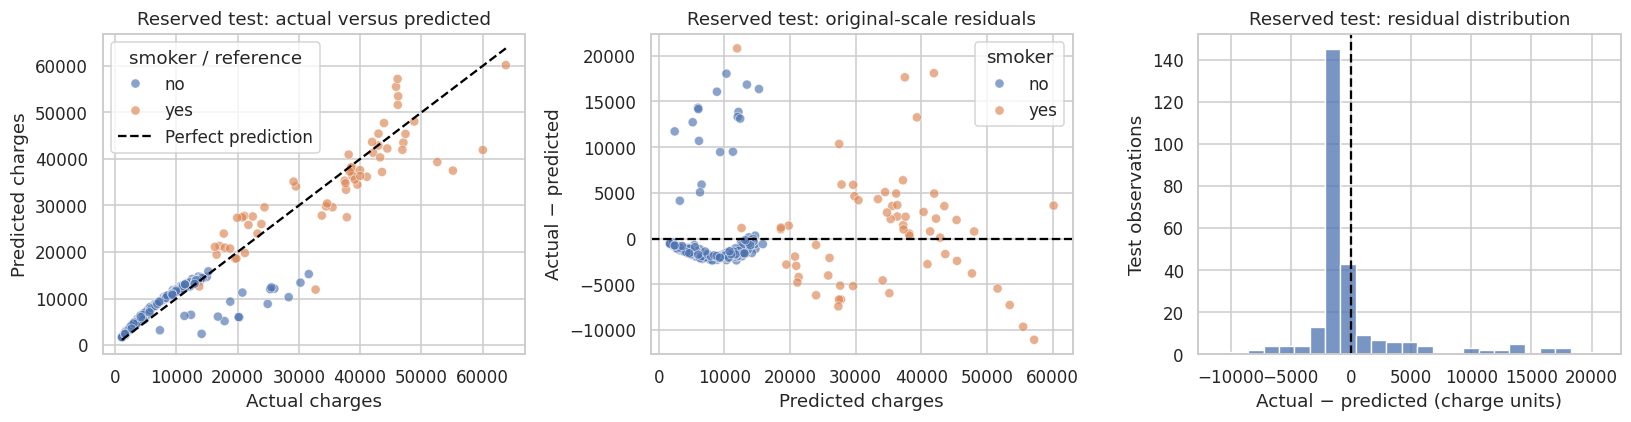

,age,sex,bmi,children,smoker,region,charges,predicted_charges,residual
23,34,female,31.92,1,yes,northeast,37701.88,33386.44,4315.43
29,31,male,36.30,2,yes,southwest,38711.00,38168.66,542.34
31,18,female,26.32,0,no,northeast,2198.19,3154.01,-955.82
32,19,female,28.60,5,no,southwest,4687.80,5409.78,-721.98
43,37,female,30.80,2,no,southeast,6313.76,8378.63,-2064.87
44,38,male,37.05,1,no,northeast,6079.67,8391.75,-2312.08
48,60,female,24.53,0,no,southeast,12629.90,13119.17,-489.27
49,36,male,35.20,1,yes,southeast,38709.18,37244.74,1464.44


In [7]:
assert selection_frozen
test_pred=predict_model(selected,test)
assert np.isfinite(test_pred).all()
test_metrics=metrics(test.charges,test_pred)
train_metrics=metrics(train.charges,predict_model(selected,train))
comparison=pd.DataFrame({"Training (optimistic)":train_metrics,"Pooled OOF":metrics(train.charges,oof[selected_name]),"Reserved test":test_metrics}).T
display(comparison.round(3))
# Training-mean predictor is an honest trivial reference on the same test rows.
mean_reference=metrics(test.charges,np.repeat(train.charges.mean(),len(test)))
print("Training-mean reference test RMSE:",round(mean_reference["RMSE"],3))
print("Negative test predictions:",int((test_pred<0).sum()))
test_results=test.assign(predicted_charges=test_pred,residual=test.charges.to_numpy()-test_pred)
subgroups=[]
for group,d in test_results.groupby("smoker"):
    subgroups.append({"smoker":group,"n":len(d),**metrics(d.charges,d.predicted_charges)})
display(pd.DataFrame(subgroups).round(3))
fig,axes=plt.subplots(1,3,figsize=(15,4))
sns.scatterplot(data=test_results,x="charges",y="predicted_charges",hue="smoker",hue_order=["no","yes"],alpha=.65,ax=axes[0])
lo=min(test.charges.min(),test_pred.min());hi=max(test.charges.max(),test_pred.max())
axes[0].plot([lo,hi],[lo,hi],color="black",ls="--",label="Perfect prediction")
axes[0].set(xlabel="Actual charges",ylabel="Predicted charges",title="Reserved test: actual versus predicted");axes[0].legend(title="smoker / reference")
sns.scatterplot(data=test_results,x="predicted_charges",y="residual",hue="smoker",hue_order=["no","yes"],alpha=.65,ax=axes[1])
axes[1].axhline(0,color="black",ls="--");axes[1].set(xlabel="Predicted charges",ylabel="Actual − predicted",title="Reserved test: original-scale residuals")
sns.histplot(data=test_results,x="residual",bins=25,ax=axes[2]);axes[2].axvline(0,color="black",ls="--")
axes[2].set(xlabel="Actual − predicted (charge units)",ylabel="Test observations",title="Reserved test: residual distribution")
show_plot(fig,"09_test_evaluation")
display(test_results[["age","sex","bmi","children","smoker","region","charges","predicted_charges","residual"]].head(8).round(2))

## 7. Results, interpretation and limitations
The narrative below is generated from this execution's numerical outputs. Associations are conditional on the included features and fitted specification, not causal effects. Raw-scale OLS coefficients are charge-unit changes; log-model coefficients are log-scale associations and must not be described as additive charge changes. A centred intercept concerns the reference categories at the fitting-data means and may not describe an observed person.

In [8]:
improvement=100*(summary.loc["OLS baseline","RMSE_mean"]-summary.loc[selected_name,"RMSE_mean"])/summary.loc["OLS baseline","RMSE_mean"]
normality=stats.jarque_bera(resid)
text=f"""### Computed conclusion
- **Selected model:** {selected_name}, chosen by the predeclared validation rule.
- **Validation:** mean fold RMSE {summary.loc[selected_name,'RMSE_mean']:,.2f} ± {summary.loc[selected_name,'RMSE_sd']:,.2f} fold SD. Improvement relative to baseline mean fold RMSE: {improvement:.2f}%.
- **Reserved test:** MAE {test_metrics['MAE']:,.2f}, RMSE {test_metrics['RMSE']:,.2f}, R² {test_metrics['R2']:.4f}, using {len(test)} observations.
- **Error interpretation:** average absolute test error is {test_metrics['MAE']:,.2f} charge units. RMSE gives extra weight to large errors; it is not the average absolute error.
- **Training influence:** {int(diagnostic.flag.sum())} records meet at least one screening guide. None were deleted.
- **Normality diagnostic:** fitted-scale training Jarque–Bera p-value {normality.pvalue:.3g}. {'This rejects normality at 0.05; exact normal-error inference is questionable.' if normality.pvalue<.05 else 'This does not reject normality at 0.05, but does not prove it.'} This diagnostic is an extension and does not determine prediction accuracy.
- **Log comparison:** {'included' if log_eligible else 'not included'} by the training-only residual-spread gate ({spread_ratio:.2f}). A gate is not proof of homoscedasticity or a transformation requirement.

### What the inspected figures support
The training charges histogram is right-skewed. Smoking-group boxplots show distinct marginal charge distributions, while the BMI scatterplot motivates different slopes by smoking status. Cross-validation favours the interaction model over the additive baseline; the log candidate has substantially larger original-scale validation errors in this execution. The original-scale log-model OOF plot shows large overpredictions, so a log transformation is not an automatic improvement.

The selected model still has structured residual bands, unequal spread and marked Q–Q departures. Its better predictive error does **not** establish a correctly specified conditional mean or classical normal, constant-variance errors. Test errors are larger for smokers by both MAE and RMSE in this execution. Cook's-distance flags identify sensitivity worth investigating, not records that should automatically be removed. The model is useful as an academic comparison, with unresolved systematic errors.

### Remaining limitations
The exact duplicate's provenance and observation independence remain unknown. The sample covers ages 18–64 and lacks diagnoses, policy details and timestamps. One fixed split cannot establish population-wide performance. CV was used to compare a small candidate set, so the winning CV estimate has selection optimism; the reserved test is the final check. No causal effects or local insurance-pricing validity are established. HC3 standard errors do not correct misspecified mean functions, dependent observations, or selection uncertainty. Residual plots must be interpreted alongside the reported errors; no plot establishes that every assumption holds.
"""
if selected_name!="OLS baseline":
    b=fit.params
    if selected_name=="Interaction OLS":
        text+=f"\n**Adjusted BMI slopes:** non-smokers {b['bmi_c']:.2f}, smokers {b['bmi_c']+b['bmi_c_x_smoker']:.2f} charge units per BMI unit, holding other included predictors fixed. These are associations.\n"
    else:
        text+=f"\n**Log-scale BMI slopes:** non-smokers {b['bmi_c']:.4f}, smokers {b['bmi_c']+b['bmi_c_x_smoker']:.4f}. Smearing factor: {selected['smear']:.4f}. A global factor may not recover conditional mean charges uniformly across groups.\n"
display(Markdown(text))

### Computed conclusion
- **Selected model:** Interaction OLS, chosen by the predeclared validation rule.
- **Validation:** mean fold RMSE 4,909.40 ± 523.12 fold SD. Improvement relative to baseline mean fold RMSE: 19.61%.
- **Reserved test:** MAE 2,828.53, RMSE 4,572.84, R² 0.8862, using 268 observations.
- **Error interpretation:** average absolute test error is 2,828.53 charge units. RMSE gives extra weight to large errors; it is not the average absolute error.
- **Training influence:** 104 records meet at least one screening guide. None were deleted.
- **Normality diagnostic:** fitted-scale training Jarque–Bera p-value 0. This rejects normality at 0.05; exact normal-error inference is questionable. This diagnostic is an extension and does not determine prediction accuracy.
- **Log comparison:** included by the training-only residual-spread gate (1.80). A gate is not proof of homoscedasticity or a transformation requirement.

### What the inspected figures support
The training charges histogram is right-skewed. Smoking-group boxplots show distinct marginal charge distributions, while the BMI scatterplot motivates different slopes by smoking status. Cross-validation favours the interaction model over the additive baseline; the log candidate has substantially larger original-scale validation errors in this execution. The original-scale log-model OOF plot shows large overpredictions, so a log transformation is not an automatic improvement.

The selected model still has structured residual bands, unequal spread and marked Q–Q departures. Its better predictive error does **not** establish a correctly specified conditional mean or classical normal, constant-variance errors. Test errors are larger for smokers by both MAE and RMSE in this execution. Cook's-distance flags identify sensitivity worth investigating, not records that should automatically be removed. The model is useful as an academic comparison, with unresolved systematic errors.

### Remaining limitations
The exact duplicate's provenance and observation independence remain unknown. The sample covers ages 18–64 and lacks diagnoses, policy details and timestamps. One fixed split cannot establish population-wide performance. CV was used to compare a small candidate set, so the winning CV estimate has selection optimism; the reserved test is the final check. No causal effects or local insurance-pricing validity are established. HC3 standard errors do not correct misspecified mean functions, dependent observations, or selection uncertainty. Residual plots must be interpreted alongside the reported errors; no plot establishes that every assumption holds.

**Adjusted BMI slopes:** non-smokers 12.44, smokers 1489.08 charge units per BMI unit, holding other included predictors fixed. These are associations.


## 8. Executable validation checks and audit
Checks independently verify metrics, least-squares predictions, leverage and Cook's distance formulas, fold coverage, group separation, and finite outputs. A deleted-observation refit checks the externally studentized residual calculation and the Cook's-distance coefficient-change definition for the most influential training observation. These checks validate calculations, not the truth of population assumptions.

All nine figures use explicitly identified partitions and scales. Plot images are embedded in this executed notebook. The accompanying delivery review also visually inspects each figure.

In [9]:
coverage=np.zeros(len(train),dtype=int)
for fi,vi in folds:
    coverage[vi]+=1
    assert set(fi).isdisjoint(vi)
    assert set(gtrain[fi]).isdisjoint(gtrain[vi])
assert (coverage==1).all()
assert set(gtrain).isdisjoint(gtest)
assert train.index.intersection(test.index).empty
j=int(np.argmax(cooks));keep=np.arange(nt)!=j
removed=sm.OLS(np.asarray(yfit)[keep],np.asarray(xsel)[keep]).fit()
deleted_s2=np.sum(removed.resid**2)/(nt-1-p)
np.testing.assert_allclose(stud_res[j],resid[j]/np.sqrt(deleted_s2*(1-h[j])),rtol=1e-8)
delta=np.asarray(fit.params)-removed.params
cook_delete=float(delta@np.asarray(xsel).T@np.asarray(xsel)@delta/(p*s2))
np.testing.assert_allclose(cooks[j],cook_delete,rtol=1e-7,atol=1e-10)
for name,model in fitted_models.items():
    if name=="Log interaction OLS":
        np.testing.assert_allclose(model["smear"],np.mean(np.exp(model["fit"].resid)),rtol=1e-12)
assert len(plot_names)==9 and len(set(plot_names))==9
assert len(cv)==5*len(candidates)
assert np.isfinite(comparison.to_numpy()).all()
print("PASS: structural validation, group isolation, five-fold coverage, independent metrics, OLS solver agreement,")
print("hat matrix, normal equations, residual scaling, deletion refit, Cook's distance and finite predictions.")
print("Figures:",plot_names)
print("Notebook execution complete. Population assumptions and dataset provenance are not independently verified.")

PASS: structural validation, group isolation, five-fold coverage, independent metrics, OLS solver agreement,
hat matrix, normal equations, residual scaling, deletion refit, Cook's distance and finite predictions.
Figures: ['01_distributions', '02_categorical_groups', '03_relationships', '04_correlations', '05_validation_comparison', '06_oof_residuals', '07_training_diagnostics', '08_cooks_distance', '09_test_evaluation']
Notebook execution complete. Population assumptions and dataset provenance are not independently verified.


## Delivery validation record

All nine code cells were executed in their listed order in a fresh IPython process, including all mathematical assertions, and rerun after review. Outputs are embedded. Native Jupyter kernel execution was attempted but the host blocked TCP and IPC socket creation; therefore this file's **standard Jupyter kernel transport was not tested here**. The same Python/IPython cell code was executed successfully without that transport.

All nine generated figures were visually inspected for data partition, axes, scale, legends, reference lines, truncation and consistency with the interpretations. Residual-comparison panels use shared axes to avoid misleading visual comparisons. Results were checked against independently calculated metric formulas, NumPy/scikit-learn least squares, hat-matrix leverage, residual scaling, and a deleted-observation refit for Cook's distance and studentization. The notebook format was validated, execution counts were checked and no error outputs remain.

This validates the execution and calculations to the extent possible in this environment. Dataset provenance, observation independence, causal validity and external-population performance remain unverified. Run Restart Kernel and Run All in your local Jupyter environment to confirm its kernel integration; the embedded dataset removes any file-path dependency.
